# Liquidity-Conditioned Short-Term Reversal
## Trading Volume and Liquidity Provision — Bianchi, Babiak & Dickerson (2022)

**Strategy family: Mean Reversal.** The strategy tests whether one-day return reversals are stronger when trading activity is unusually low relative to a cryptocurrency's recent history. It buys the recent losers and sells the recent winners within low-, middle-, and high-volume-shock groups.

A possible economic explanation is that some short-term price movements reflect temporary buying or selling pressure. Traders taking the opposite side supply liquidity while bearing inventory and adverse-selection risk. The paper's evidence is consistent with this interpretation, but it does not imply that every low-volume price move will reverse.

Here is the trading process:

1. **Prepare the daily universe.** Start with the fixed 30 cryptocurrencies and align their daily OHLCV and market-capitalization histories. Zero or nonfinite volume and volume-to-market-cap ratios above one are treated as unavailable signals for the affected coin-day. The volume benchmark tolerates isolated screened days: it needs at least 80% valid observations in its trailing window.

2. **Measure the formation-day return.** At formation close $t$, rank coins using the return realized over day $t$ (close $t-1$ to close $t$). This is the same day as the volume signal, matching the paper's Eq. (2), in which $y_{i,t+1}$ is predicted by $y_{i,t}$ and $v_{i,t}$. A skip-day variant and the earlier misaligned pairing are reported only as declared sensitivities.

3. **Measure abnormal trading activity.** Compare each coin's volume at $t$ with the arithmetic mean of its previous 30 calendar days, then standardize that log-volume deviation by the trailing standard deviation of log volume. A 60-day window is retained as a robustness check.

4. **Build the 3×3 sequential sort.** Divide the valid coins into low-, middle-, and high-return terciles. Within each return tercile, sort again into low-, middle-, and high-volume-shock groups. A coin with an invalid signal is excluded from that day's sort without forcing the remaining universe into cash.

5. **Form the conditional reversal portfolios.** Within each volume group, buy the low-return cell and short the high-return cell. Build low-, middle-, and high-volume reversal portfolios using both equal-weighted and market-cap-weighted legs, with +100% long exposure and −100% short exposure.

6. **Rebalance and pay implementation costs.** Weights formed at close $t$ earn the close-to-close return from $t$ to $t+1$. Portfolios rebalance daily and pay 20 basis points per dollar of asset notional traded, including entries, rebalances, and each segment's final liquidation.

7. **Evaluate without retuning.** The fixed backtest runs from 2021-01-02 through 2024-12-31; validation runs from 2025-01-01 through 2026-09-17. Signal warm-up remains inside those dates as cash, and the same rules apply to both periods. Performance statistics are computed on active dates only, so warm-up cash days do not dilute means, t-statistics, or Sharpe ratios.

**Paper:** Bianchi, D., Babiak, M., & Dickerson, A. (2022). *Trading Volume and Liquidity Provision in Cryptocurrency Markets*. Journal of Banking & Finance, 142, 106547. [Published paper](https://doi.org/10.1016/j.jbankfin.2022.106547) · [Accepted manuscript](https://eprints.lancs.ac.uk/id/eprint/172093/1/Babiak_Trading_Volume.pdf).

**Fixed research dates:** prices run from **2021-01-01 through 2026-09-17**. Strategy returns use a fixed chronological 70/30 split: **Backtest 2021-01-02 through 2024-12-31** and **Validation 2025-01-01 through 2026-09-17**.

Run all cells in order. The shared inputs are `OHLCV_Market_Cap_Data/crypto_30_coin_daily_ohlcv.csv` and `OHLCV_Market_Cap_Data/crypto_30_coin_daily_market_cap_supply.csv`.

## 1. Research design and experiment map

The paper asks whether short-term reversal is stronger when trading activity is low relative to each coin's recent history. This notebook tests that idea on the same fixed 30-coin universe, common CoinMarketCap inputs, and chronological backtest/validation split used by the other strategy notebooks.

The primary research question is whether **low-volume reversal** is stronger than the corresponding middle- and high-volume reversal portfolios. The experiment map contains the sequential 3×3 sort, single-sort benchmarks, equal- and value-weighted portfolios, gross and net performance, and a 60-day volume-window robustness check. Low-volume reversal is the predeclared paper strategy; validation does not select or retune it.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from IPython.display import display, Markdown
import warnings

NOTEBOOK_NAME = "Trading_Vol_and_Liquidity_Bianchi_et_al.ipynb"
# Input and output paths are relative to the extracted repository folder.
# Open that folder as your IDE project and start the kernel there.
NOTEBOOK_DIR = Path(".")
DATA_DIR = Path("OHLCV_Market_Cap_Data")
OUTPUT_ROOT = Path("output") / "liquidity_provision"

SAMPLE_START = "2021-01-01"
SAMPLE_END = "2026-09-17"
BACKTEST_START, BACKTEST_END = "2021-01-02", "2024-12-31"
VALIDATION_START, VALIDATION_END = "2025-01-01", "2026-09-17"
#Standard 70-30 Backtest Validation Split

VOLUME_WINDOW = 30
# Volume at formation date t is compared with the arithmetic mean of raw volume over the preceding 30 calendar days.

VOLUME_WINDOW_ROBUSTNESS = 60
# Recalculates the volume shock using 60 prior days to test whether results depend on choosing 30.

VOLUME_MIN_OBS_FRACTION = 0.8
# A volume-shock signal needs at least 80% valid observations in its trailing window (24 of 30, 48 of 60).
# Requiring 100% let one screened coin-day erase the next m days of signal for that coin.

WASH_TRADE_RATIO = 1.0  # paper's screen: volume / market cap above this marks an invalid coin-day
PAPER_MEDIAN_VOLUME_TO_CAP = 0.001  # median reported by Bianchi et al. (2022); diagnostic reference only

MIN_VALID_ASSETS = 9  # need at least this many coins with a valid signal to trade a 3x3 sort that day

COST_BPS = 20
COST_RATE = COST_BPS / 10_000
PERIODS_PER_YEAR = 365
HAC_LAGS = 20


STRATEGIES = {
    "lvr": "Low-volume reversal",
    "mvr": "Middle-volume reversal",
    "hvr": "High-volume reversal",
}
LABELS = STRATEGIES.copy()
COLORS = {"lvr": "#176b87", "mvr": "#d08a35", "hvr": "#8555a6"}
WEIGHTINGS = {"equal": "Equal-weighted", "value": "Value-weighted"}


#Just some simple color scheme adjustments! Thank the AI Overlords!

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "#fcfcfd",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#d1d5db", "axes.labelcolor": "#374151", "text.color": "#1f2937",
    "xtick.color": "#64748b", "ytick.color": "#64748b", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "grid.alpha": 0.25,
    "grid.color": "#cbd5e1", "legend.frameon": False,
})
FIGURES = {}

def polish_axis(ax, date_axis=False, zero_line=False):
    ax.grid(axis="y", linewidth=0.6)
    ax.set_axisbelow(True)
    if zero_line:
        ax.axhline(0, color="#64748b", linewidth=0.8, zorder=0)
    if date_axis:
        locator = mdates.AutoDateLocator(minticks=3, maxticks=8)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

def show_figure(fig, name, title, subtitle):
    height_points = fig.get_figheight() * 72
    fig.text(0.06, 0.99, title, ha="left", va="top", fontsize=15)
    fig.text(0.06, 0.99 - 23 / height_points, subtitle, va="top", fontsize=9, color="#64748b")
    fig.tight_layout(rect=[0.015, 0.015, 0.985, 0.99 - 43 / height_points], w_pad=2.5, h_pad=2.5)
    FIGURES[name] = fig
    plt.show()
    plt.close(fig)

In [2]:
# Fixed 30-coin universe, grouped by economic category
SECTORS = {
    "Store of Value / Benchmark": ["BTC-USD"],
    "Layer 1 Smart Contracts": ["ETH-USD", "SOL-USD", "BNB-USD", "ADA-USD", "AVAX-USD", "DOT-USD", "NEAR-USD", "ATOM-USD", "TRX-USD", "ALGO-USD", "HBAR-USD"],
    "Payments & Legacy": ["XRP-USD", "DOGE-USD", "LTC-USD", "BCH-USD", "ETC-USD", "XLM-USD"],
    "DeFi Protocols": ["AAVE-USD", "MKR-USD", "UNI7083-USD", "CRV-USD", "INJ-USD", "RUNE-USD"],
    "Infrastructure, Storage & Metaverse": ["LINK-USD", "FIL-USD", "VET-USD", "THETA-USD", "SAND-USD", "MANA-USD"],
}

tickers = [ticker for members in SECTORS.values() for ticker in members]
ASSETS = sorted("UNI-USD" if ticker == "UNI7083-USD" else ticker for ticker in tickers)
assert len(ASSETS) == len(set(ASSETS)) == 30
display(pd.DataFrame([
    {"Category": sector, "Coins": ", ".join(t.replace("7083", "").replace("-USD", "") for t in members)}
    for sector, members in SECTORS.items()
]))


,Category,Coins
0,Store of Value / Benchmark,BTC
1,Layer 1 Smart Contracts,"ETH, SOL, BNB, ADA, AVAX, DOT, NEAR, ATOM, TRX..."
2,Payments & Legacy,"XRP, DOGE, LTC, BCH, ETC, XLM"
3,DeFi Protocols,"AAVE, MKR, UNI, CRV, INJ, RUNE"
4,"Infrastructure, Storage & Metaverse","LINK, FIL, VET, THETA, SAND, MANA"


In [3]:
INPUT_PATH = DATA_DIR / "crypto_30_coin_daily_ohlcv.csv"
MCAP_PATH = DATA_DIR / "crypto_30_coin_daily_market_cap_supply.csv"
for path in [INPUT_PATH, MCAP_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing bundled input: {path.relative_to(NOTEBOOK_DIR).as_posix()}. "
        "Open the fully extracted repository folder as your IDE project and set the kernel working directory there. "
        "If this folder is already correct, restore the missing CSV from the repository input files.")

# Hash and parse the exact shared files used by the other strategy notebooks.
input_bytes = INPUT_PATH.read_bytes()
mcap_bytes = MCAP_PATH.read_bytes()
input_hashes = {INPUT_PATH.name: hashlib.sha256(input_bytes).hexdigest(),
                MCAP_PATH.name: hashlib.sha256(mcap_bytes).hexdigest()}
market_data = pd.read_csv(BytesIO(input_bytes))
required_columns = {"date", "symbol", "open", "high", "low", "close", "volume"}
if not required_columns.issubset(market_data.columns):
    raise ValueError(f"Missing input columns: {sorted(required_columns - set(market_data.columns))}")
market_data["date"] = pd.to_datetime(market_data["date"], format="%Y-%m-%d", errors="raise")
if market_data["date"].isna().any() or market_data["symbol"].isna().any():
    raise ValueError("Missing dates or symbols in the shared input.")
if market_data.duplicated(["date", "symbol"]).any():
    raise ValueError("Duplicate date/symbol observations in the shared input.")
expected_symbols = {asset.removesuffix("-USD") for asset in ASSETS}
if set(market_data["symbol"]) != expected_symbols:
    raise ValueError("The input must contain exactly the fixed 30-coin universe.")
for field in ["open", "high", "low", "close", "volume"]:
    market_data[field] = pd.to_numeric(market_data[field], errors="raise")

market_data["asset"] = market_data["symbol"] + "-USD"
prices = market_data.pivot(index="date", columns="asset", values="close").sort_index()
volume = market_data.pivot(index="date", columns="asset", values="volume").sort_index()
opens = market_data.pivot(index="date", columns="asset", values="open").sort_index()
highs = market_data.pivot(index="date", columns="asset", values="high").sort_index()
lows = market_data.pivot(index="date", columns="asset", values="low").sort_index()
for label, frame in [("prices", prices), ("volume", volume), ("opens", opens), ("highs", highs), ("lows", lows)]:
    if set(frame.columns) != set(ASSETS):
        raise ValueError(f"{label}: input must contain exactly the fixed 30 assets.")
    if not frame.index.is_unique or not frame.index.is_monotonic_increasing:
        raise ValueError(f"{label}: dates must be sorted and unique.")

mcap_data = pd.read_csv(BytesIO(mcap_bytes))
if not {"date", "symbol", "market_cap"}.issubset(mcap_data.columns):
    raise ValueError("Missing input columns in the market-cap file.")
mcap_data["date"] = pd.to_datetime(mcap_data["date"], format="%Y-%m-%d", errors="raise")
mcap_data["market_cap"] = pd.to_numeric(mcap_data["market_cap"], errors="raise")
mcap_data["asset"] = mcap_data["symbol"] + "-USD"
market_cap = mcap_data.pivot(index="date", columns="asset", values="market_cap").sort_index()
if set(market_cap.columns) != set(ASSETS):
    raise ValueError("market_cap: input must contain exactly the fixed 30 assets.")

frames = {"prices": prices, "volume": volume, "opens": opens, "highs": highs, "lows": lows, "market_cap": market_cap}
for label in frames:
    frames[label] = frames[label].loc[SAMPLE_START:SAMPLE_END, ASSETS].copy()
prices, volume, opens, highs, lows, market_cap = (frames[k] for k in ["prices", "volume", "opens", "highs", "lows", "market_cap"])
for label, frame in frames.items():
    if not frame.index.equals(prices.index):
        raise ValueError(f"{label}: dates differ from the price index.")
expected_calendar = pd.date_range(SAMPLE_START, SAMPLE_END, freq="D")
if not prices.index.equals(expected_calendar):
    raise ValueError("The shared input must contain every calendar day in the declared sample.")
if not np.isfinite(prices.to_numpy()).all() or (prices <= 0).any().any():
    raise ValueError("Nonpositive or missing prices require review; prices are not imputed.")

# A zero, negative, or missing market cap is treated as an invalid signal for that coin-day
# (not imputed) -- MKR is missing/zero for most of 2025 onward, NEAR for one day in 2021.
market_cap = market_cap.where(np.isfinite(market_cap) & (market_cap > 0))

raw_volume = volume.copy()
bad_volume = ~np.isfinite(raw_volume) | (raw_volume <= 0)
bad_rows, bad_cols = np.where(bad_volume.to_numpy())
volume_issues = pd.DataFrame({
    "date": raw_volume.index[bad_rows], "asset": raw_volume.columns[bad_cols],
    "observed_volume": raw_volume.to_numpy()[bad_rows, bad_cols],
})

# Paper's screen : drop a pair-day if volume / market_cap exceeds 1 (catches apparent wash-trading / data errors).
# Applied here as an additional invalid-signal mask on top of the zero/negative volume screen, using the same "missing signal" architecture --
# every downstream rolling/shock/factor computation already tolerates NaN volume gracefully.

volume_to_cap_ratio = raw_volume / market_cap
wash_trade_flagged = (volume_to_cap_ratio > WASH_TRADE_RATIO).fillna(False)
wash_rows, wash_cols = np.where(wash_trade_flagged.to_numpy())
wash_trade_issues = pd.DataFrame({
    "date": raw_volume.index[wash_rows], "asset": raw_volume.columns[wash_cols],
    "volume_to_market_cap": volume_to_cap_ratio.to_numpy()[wash_rows, wash_cols],
})
volume = raw_volume.mask(wash_trade_flagged)

returns = prices.pct_change(fill_method=None).iloc[1:]
observed_returns = prices.pct_change(fill_method=None)

bad_mcap = market_cap.isna()
bad_mcap_rows, bad_mcap_cols = np.where(bad_mcap.to_numpy())
market_cap_issues = pd.DataFrame({
    "date": market_cap.index[bad_mcap_rows], "asset": market_cap.columns[bad_mcap_cols],
})
print(f"Loaded {len(ASSETS)} coins and {len(prices):,} daily observations from {SAMPLE_START} through {SAMPLE_END}.")
print(f"Invalid (zero/negative/nonfinite) volume observations retained as missing signals: {len(volume_issues):,}.")
print(f"Wash-trade-screened observations (volume/market_cap > 1) retained as missing signals: "
      f"{len(wash_trade_issues):,} ({wash_trade_issues['asset'].nunique() if len(wash_trade_issues) else 0} coin(s) affected).")
print(f"Invalid market-cap observations retained as missing signals: {len(market_cap_issues):,} ({market_cap_issues['asset'].nunique()} coin(s) affected).")
display (prices)
display (market_cap)

# ---- Volume-quality diagnostic ----
# The paper reports a median volume / market cap of ~0.001 on CryptoCompare's AA-B exchange set.
# CoinMarketCap aggregate volume is far higher, so the level gap is documented here rather than hidden.
volume_quality = pd.DataFrame({
    "Median volume / market cap": volume_to_cap_ratio.median(),
    "95th pct volume / market cap": volume_to_cap_ratio.quantile(0.95),
    "Max volume / market cap": volume_to_cap_ratio.max(),
    "Days flagged (> 1)": wash_trade_flagged.sum(),
    "Flagged (%)": 100 * wash_trade_flagged.mean(),
}).sort_values("Median volume / market cap", ascending=False)
volume_quality["Median vs paper (x)"] = volume_quality["Median volume / market cap"] / PAPER_MEDIAN_VOLUME_TO_CAP
pooled_median_ratio = float(np.nanmedian(volume_to_cap_ratio.to_numpy()))
print(f"Pooled median volume/market cap: {pooled_median_ratio:.4f} versus the paper's {PAPER_MEDIAN_VOLUME_TO_CAP} "
      f"(~{pooled_median_ratio / PAPER_MEDIAN_VOLUME_TO_CAP:.0f}x).")
display(volume_quality)


Loaded 30 coins and 2,086 daily observations from 2021-01-01 through 2026-09-17.
Invalid (zero/negative/nonfinite) volume observations retained as missing signals: 2.
Wash-trade-screened observations (volume/market_cap > 1) retained as missing signals: 264 (18 coin(s) affected).
Invalid market-cap observations retained as missing signals: 486 (4 coin(s) affected).


asset,AAVE-USD,ADA-USD,ALGO-USD,ATOM-USD,AVAX-USD,BCH-USD,BNB-USD,BTC-USD,CRV-USD,DOGE-USD,...,NEAR-USD,RUNE-USD,SAND-USD,SOL-USD,THETA-USD,TRX-USD,UNI-USD,VET-USD,XLM-USD,XRP-USD
date,,,,,,,,,,,,,,,,,,,,,
2021-01-01,90.3497,0.1753,0.3981,5.8686,3.6648,341.9856,37.9050,29374.1519,0.6223,0.0057,...,1.3573,1.2940,0.0370,1.8421,1.9715,0.0269,4.7362,0.0191,0.1324,0.2374
2021-01-02,85.7128,0.1774,0.4081,5.4146,3.4949,354.5999,38.2416,32127.2679,0.6142,0.0106,...,1.4097,1.2934,0.0381,1.7993,2.4004,0.0272,4.8452,0.0200,0.1278,0.2217
2021-01-03,91.0966,0.2050,0.4228,5.8139,3.4729,421.7899,41.1490,32782.0245,0.6723,0.0098,...,1.4727,1.4815,0.0410,2.1618,2.1214,0.0295,5.4470,0.0259,0.1364,0.2258
2021-01-04,111.1320,0.2248,0.4387,5.9968,3.5902,407.9369,40.9264,31971.9135,0.6770,0.0098,...,1.3837,1.5902,0.0405,2.4851,1.9603,0.0309,5.4066,0.0247,0.1652,0.2367
2021-01-05,116.4538,0.2583,0.4794,6.2168,4.2374,419.7681,41.7346,33992.4293,0.6870,0.0099,...,1.5020,1.5842,0.0418,2.1572,2.1340,0.0286,6.2793,0.0279,0.1948,0.2268
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-13,124.3454,0.2036,0.0945,1.5816,7.2914,220.8770,716.3305,76838.1552,0.3455,0.0824,...,2.2993,0.5066,0.0352,99.2458,0.2025,0.3383,6.1146,0.0077,0.1771,1.3406
2026-09-14,128.2388,0.2086,0.0960,1.5807,7.5613,223.3209,720.2359,78163.3802,0.3470,0.0836,...,2.4648,0.5186,0.0356,102.4951,0.1956,0.3381,6.5297,0.0076,0.1912,1.4210
2026-09-15,122.1809,0.1954,0.0888,1.5182,7.2735,216.9672,712.1606,75612.5110,0.3203,0.0801,...,2.3349,0.4893,0.0335,96.8884,0.1798,0.3328,6.3760,0.0071,0.1761,1.2847


asset,AAVE-USD,ADA-USD,ALGO-USD,ATOM-USD,AVAX-USD,BCH-USD,BNB-USD,BTC-USD,CRV-USD,DOGE-USD,...,NEAR-USD,RUNE-USD,SAND-USD,SOL-USD,THETA-USD,TRX-USD,UNI-USD,VET-USD,XLM-USD,XRP-USD
date,,,,,,,,,,,,,,,,,,,,,
2021-01-01,1087592822.2174,5455571952.5957,475506413.9947,1221517403.5380,281960682.5150,6361227988.9677,5473732252.4390,546001594837.5117,96647228.5958,726323310.6655,...,267271665.5469,205018157.7678,23020017.1652,85785758.3765,1971477307.8242,1930480208.2790,1273682447.7947,1227148151.4250,2901669479.1338,10780931627.2557
2021-01-02,1032020483.2481,5520054873.2087,488214115.6519,1127305816.2343,268890417.5598,6595864637.6039,5522336921.9573,597205944668.8502,95380247.5081,1356280739.9393,...,277582620.3676,204909568.5736,23714860.4486,83792133.5388,2400356532.8932,1950520169.5318,1303181237.0459,1285334118.0690,2801127005.3624,10064026551.1043
2021-01-03,1097389994.1442,6377915101.9116,506613483.1901,1210730092.4054,267198080.1840,7845655333.3767,5942182740.6619,609409213147.0334,104403922.0462,1248577459.1099,...,289994369.5752,234709777.2465,25465023.5150,100672674.8118,2121383111.8456,2113567006.5798,1465283748.2642,1667128428.6949,2989656210.8863,10254417776.8028
2021-01-04,1339476346.3390,6992916198.9984,526536585.8972,1249114393.8646,276222731.5713,7587978844.8150,5910034133.6068,594384025390.8551,105134275.3449,1248286672.3342,...,272463181.0164,251942743.8598,25178243.9034,115730856.1860,1960264023.0018,2210899235.1473,1454876039.8154,1586334769.1906,3621839340.1160,10746094507.9997
2021-01-05,1404342547.2497,8036779510.7535,576420575.5928,1295265100.7068,326014027.0262,7808049335.5453,6026750036.7700,631980005969.6278,106692048.2996,1268003963.9314,...,295753867.2664,250980765.5273,25966542.6026,100461485.6707,2133997503.3921,2051773562.1667,1689967870.7868,1795012177.0620,4276293447.6286,10295369035.4138
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-13,1918382569.0800,7481356407.1100,854407090.5500,838405082.1600,3226463740.8300,4437232528.2700,95388227202.5500,1543059626534.4199,537478127.6800,14144868900.5900,...,3003486037.4700,166483032.0800,103270853.0700,58233043941.5600,202508909.1100,32122296999.1600,3800216061.2800,659723234.1000,6170368971.2900,84297230822.2600
2026-09-14,1978426963.6800,7664386250.2800,867969251.3700,838389015.5600,3345937806.2600,4486334343.7400,95907081028.4200,1569851167120.1001,539885852.5700,13039724580.5800,...,3219804378.3700,170430439.7200,104601466.0700,60153677415.4400,195601573.1200,32099595852.2900,4057462892.9000,657145533.3000,6659949842.5400,89354196723.0900
2026-09-15,1884947624.7500,7180831478.3400,803224489.1400,805512487.3800,3220730154.7200,4358791844.5700,94832123157.4600,1518660066021.8999,498393124.3100,13744644878.6000,...,3050388796.0500,160799272.7300,98367336.2500,56876584013.7200,179817965.4600,31601979189.9200,3961453193.3200,608100139.7100,6136098764.0000,80780637058.9100


Pooled median volume/market cap: 0.0576 versus the paper's 0.001 (~58x).


,Median volume / market cap,95th pct volume / market cap,Max volume / market cap,Days flagged (> 1),Flagged (%),Median vs paper (x)
asset,,,,,,
CRV-USD,0.1775,0.5379,2.8953,13,0.6232,177.5329
SAND-USD,0.1355,0.6930,5.9836,57,2.7325,135.5055
INJ-USD,0.1045,0.3298,2.0910,5,0.2397,104.5375
RUNE-USD,0.1040,0.3555,2.9665,16,0.7670,104.0486
AAVE-USD,0.1018,0.2656,0.6880,0,0.0000,101.8106
FIL-USD,0.0990,0.3449,1.5687,6,0.2876,99.0068
MANA-USD,0.0910,0.3262,4.2573,13,0.6232,90.9903
LTC-USD,0.0879,0.4049,1.9506,11,0.5273,87.8594
LINK-USD,0.0725,0.2195,16.5148,1,0.0479,72.5202


## 2. Volume shock and signal timing

This section prepares the two signals used by the sequential 3×3 portfolio sort; it does not form positions yet. For coin $i$ and formation date $t$, $P_{i,t}$ is the closing price and $V_{i,t}$ is reported dollar volume after the data-quality screens. A volume observation is usable only when it is finite and strictly positive. Write that cleaned observation as $\widetilde V_{i,t}$.

### Volume-shock equations

For a trailing window of $m=30,60$ days, the historical volume benchmark excludes the current date:

$$
\overline V_{i,t-1}^{(m)}=\frac{1}{m}\sum_{s=1}^{m}\widetilde V_{i,t-s}.
$$

The denominator is the **sample standard deviation of prior log-volume levels** over the same window:

$$
s_{i,t-1}^{(m)}=\operatorname{std}_{\mathrm{sample}}\!\left(
\log \widetilde V_{i,t-m},\ldots,\log \widetilde V_{i,t-1}
\right).
$$

The standardized volume shock is

$$
v_{i,t}^{(m)}=
\frac{\log \widetilde V_{i,t}-\log \overline V_{i,t-1}^{(m)}}
{s_{i,t-1}^{(m)}}.
$$

The order of operations matters: the numerator takes the log of the **arithmetic mean of raw historical volume**; it does not take the mean of historical log volume. The primary signal uses $m=30$, while $m=60$ is retained as a robustness check. The current observation never enters its own benchmark or standard deviation. The rolling statistics require at least $\lceil 0.8m\rceil$ valid observations inside the $m$-day window (24 of 30, 48 of 60); when a few days are screened out, the mean and standard deviation use the valid days that remain. An unavailable current volume, fewer than $\lceil 0.8m\rceil$ valid historical days, or a zero historical log-volume standard deviation produces no signal for that coin-date. A strict 100%-complete window would let a single screened coin-day erase the next $m$ days of signal, which multiplied the data lost to the wash-trade screen roughly sixfold; the coverage table in the next cell quantifies this.

### Return signal and trading clock

Daily simple returns are

$$
r_{i,t}=\frac{P_{i,t}}{P_{i,t-1}}-1.
$$

The portfolio sort uses the return realized over the formation day itself,

$$
q_{i,t}=r_{i,t}=\frac{P_{i,t}}{P_{i,t-1}}-1,
$$

together with the **same-day** volume shock $v_{i,t}^{(30)}$. Both are known at the close of day $t$ (00:00 UTC), and the resulting weights become live on $t+1$ and earn the close-to-close return $r_{i,t+1}$. This is the alignment in the paper's panel regression, Eq. (2), $y_{i,t+1}=\alpha_i+\tau_t+\beta_1 y_{i,t}+\beta_2 v_{i,t}+\beta_3 y_{i,t}v_{i,t}+\dots$, and in the paper's description of the volume signal as *contemporaneous to* the return signal. Execution is assumed at the same close that defines the signal, as in the paper's 00:00 UTC rebalance.

**Why this changed (specification v5).** Specification v4 sorted on $r_{i,t-1}$ together with $v_{i,t}$. That pairing is not contemporaneous under any reading of the paper: if "lagged return" refers to $r_{i,t-1}$, the matching volume signal is $v_{i,t-1}$. Two alternatives are evaluated as **declared sensitivities** in §6 and are never used to choose the primary specification:

| Variant | Return signal | Volume signal | Purpose |
|---|---|---|---|
| Primary | $r_{i,t}$ | $v_{i,t}$ | Paper Eq. (2) alignment |
| Skip-day aligned | $r_{i,t-1}$ | $v_{i,t-1}$ | Skips the most recent day, a standard bid-ask-bounce / stale-close control |
| Legacy hybrid (v4) | $r_{i,t-1}$ | $v_{i,t}$ | Misaligned pairing, retained for audit only |

### Volume data quality

CoinMarketCap aggregate volume is much larger relative to market cap than the paper's CryptoCompare AA–B exchange volume (the diagnostic table in §1 reports the per-coin medians against the paper's 0.001). Two features of the design limit how much this level gap can contaminate the signal:

1. $v_{i,t}$ is a **within-coin** log deviation scaled by the coin's own log-volume dispersion. A persistent multiplicative inflation of reported volume, $\widetilde V_{i,t}=k_i V_{i,t}$, cancels exactly from both the numerator and denominator. Only time-varying contamination enters the signal.
2. Portfolios are formed from **cross-sectional ranks**, so isolated extreme shocks change at most one coin's bucket.

The paper's screen is to drop a pair entirely if its volume ever exceeds its market cap. On this fixed universe that rule would remove 18 of the 30 coins, so it is applied at coin-day level instead: flagged days are treated as missing volume, and the 80% window rule stops each flagged day from silencing the following month of signal. This is a disclosed deviation from the paper.

The declared backtest and validation boundaries are used exactly as configured; signal warm-up never moves those boundaries, and dates without enough valid signals simply remain flat.

### Equation-to-code map

| Strategy symbol | Code variable | Meaning |
|---|---|---|
| $P_{i,t}$ | `prices` | Closing-price panel |
| $V_{i,t}$ | `volume` / `volume_frame` | Screened dollar-volume panel supplied to the function |
| $\widetilde V_{i,t}$ | `clean` | Finite, strictly positive volume; otherwise missing |
| $m=30$ | `VOLUME_WINDOW` | Primary volume-shock window |
| $m=60$ | `VOLUME_WINDOW_ROBUSTNESS` | Robustness window |
| $\overline V_{i,t-1}^{(m)}$ | `trailing_mean` | Arithmetic mean of the preceding $m$ raw-volume observations |
| $s_{i,t-1}^{(m)}$ | `trailing_log_std` | Sample standard deviation of the preceding $m$ log-volume levels |
| $v_{i,t}^{(m)}$ | `shock` | Standardized volume shock returned by the function |
| $v_{i,t}^{(30)}$ | `volume_shock` | Primary volume-shock signal |
| $v_{i,t}^{(60)}$ | `volume_shock_m60` | Robustness volume-shock signal |
| $r_{i,t}$ | `observed_returns` | Daily simple return aligned to date $t$ |
| $q_{i,t}=r_{i,t}$ | `return_signal` | Formation-day return used by the portfolio sort at date $t$ |
| — | `TIMING_VARIANTS` | Declared timing sensitivities (skip-day aligned, legacy hybrid) |
| — | `VOLUME_MIN_OBS_FRACTION` | Minimum share of valid days in the trailing volume window (0.8) |

In [4]:
def compute_volume_shock(volume_frame, window, min_obs_fraction=VOLUME_MIN_OBS_FRACTION):
    # volume_frame: date-by-coin screened volume; window: m = 30 or 60.
    # min_obs_fraction: share of the m trailing days that must hold a valid volume (default 80%).
    clean = volume_frame.where(np.isfinite(volume_frame) & (volume_frame > 0))
    min_obs = int(np.ceil(min_obs_fraction * window))
    history = clean.shift(1)  # the current day never enters its own benchmark or dispersion
    trailing_mean = history.rolling(window, min_periods=min_obs).mean()
    trailing_log_std = np.log(history).rolling(window, min_periods=min_obs).std(ddof=1)
    shock = (np.log(clean) - np.log(trailing_mean)) / trailing_log_std.where(trailing_log_std > 0)
    # Taking an extra cautionary step to prevent division by zero.

    return shock.replace([np.inf, -np.inf], np.nan)
    # Replaces any remaining infinite results with missing values and returns the volume-shock table.


volume_shock = compute_volume_shock(volume, VOLUME_WINDOW)
volume_shock_m60 = compute_volume_shock(volume, VOLUME_WINDOW_ROBUSTNESS)

# Primary timing (paper Eq. 2): at formation close t, sort on the return realized over day t
# (close t-1 -> close t) and the volume shock of the same day t; the weights earn r_{t+1}.
return_signal = observed_returns

# Declared timing sensitivities -- evaluated and reported, never used to select the primary specification.
TIMING_VARIANTS = {
    "skip": ("Skip-day aligned: r(t-1), v(t-1)", observed_returns.shift(1), volume_shock.shift(1)),
    "hybrid": ("Legacy hybrid (v4): r(t-1), v(t)", observed_returns.shift(1), volume_shock),
}

# Coverage audit: post-warm-up coin-days without a volume signal under a strict 100%-complete window
# versus the 80% rule used here.
post_warmup = prices.index[VOLUME_WINDOW + 1:]
strict_shock = compute_volume_shock(volume, VOLUME_WINDOW, min_obs_fraction=1.0)
signal_coverage = pd.DataFrame({
    "Screened coin-days": int((bad_volume | wash_trade_flagged).sum().sum()),
    "Coin-days without a volume signal (post warm-up)": [
        int(strict_shock.loc[post_warmup].isna().sum().sum()),
        int(volume_shock.loc[post_warmup].isna().sum().sum())],
}, index=[f"Strict window ({VOLUME_WINDOW}/{VOLUME_WINDOW} valid days)",
          f"Used ({int(np.ceil(VOLUME_MIN_OBS_FRACTION * VOLUME_WINDOW))}/{VOLUME_WINDOW} valid days)"])
display(signal_coverage)


,Screened coin-days,Coin-days without a volume signal (post warm-up)
Strict window (30/30 valid days),266,1553
Used (24/30 valid days),266,402


## 3. Sequential sorts and portfolio weights

At formation close $t$, the strategy uses the formation-day return signal $q_{i,t}=r_{i,t}$ and the same-day volume shock $v_{i,t}$ defined in §2. It first sorts eligible coins by return and then sorts again by volume **within each return group**.

All signal, market-cap, group, and weight panels use dates as rows and coins as columns. Selecting one date therefore produces a cross-sectional `Series` indexed by coin.

### Function inputs and rank helpers

| Code variable | Data structure | Meaning |
|---|---|---|
| `values` | Coin-indexed `Series` | One date's signal values passed to a ranking helper |
| `ranks` | Coin-indexed `Series` | Ascending ranks; `method="first"` resolves ties by existing coin order |
| `return_sig` | Date × coin `DataFrame` | Formation-day return signal $q_{i,t}=r_{i,t}$ |
| `shock_sig` | Date × coin `DataFrame` | Standardized volume shock $v_{i,t}$ |
| `market_cap_frame` | Date × coin `DataFrame` | Market capitalization $MC_{i,t}$ used for eligibility and value weights |
| `signal_frame` | Date × coin `DataFrame` | Single characteristic supplied to the benchmark sort |
| `weighting` | String | `"equal"` or `"value"`; equal weighting is the default |
| `min_valid` | Integer | Minimum eligible coins required to form a portfolio; currently 9 |

| Helper | Quantiles | Returned labels | Used for |
|---|---:|---|---|
| `tercile_labels(values)` | 3 | `0`, `1`, `2` from low to high | Return terciles and conditional volume terciles |
| `decile_labels(values)` | 10 | `0` through the highest available label | Single-sort `rev` and `volshock` benchmarks |

`qcut` targets approximately equal **numbers of coins**, not equally spaced signal ranges. With 30 eligible coins, the first tercile sort normally produces 10 coins per group and the decile sort about 3 per group. The second tercile sort is performed inside each return group, so a 10-coin return group is typically divided 4–3–3. Counts change when fewer coins are eligible.


### Eligibility and group assignment

For equal weighting, a coin is eligible when both signals are available. Value weighting additionally requires a valid market capitalization $MC_{i,t}$:

$$
\mathcal E_t^{\mathrm{EW}}=\{i:q_{i,t},v_{i,t}\text{ are valid}\},
\qquad
\mathcal E_t^{\mathrm{VW}}=\{i\in\mathcal E_t^{\mathrm{EW}}:MC_{i,t}\text{ is valid}\}.
$$

Formation occurs only when $|\mathcal E_t|\geq N_{\min}=9$. Eligible coins enter return terciles $R_{i,t}\in\{0,1,2\}$ from low to high. Within each return tercile, they enter volume-shock terciles $G_{i,t}\in\{0,1,2\}$ from low to high. Ties follow the fixed alphabetical asset order.

### Cell weights

Let $\mathcal C_{g,h,t}=\{i:R_{i,t}=g,\ G_{i,t}=h\}$ denote one of the nine return–volume cells. Its long-only weight is

$$
a_{i,t}^{(g,h)}=
\begin{cases}
1/|\mathcal C_{g,h,t}|, & \text{equal weighted},\\
MC_{i,t}/\sum_{j\in\mathcal C_{g,h,t}}MC_{j,t}, & \text{value weighted},\\
0, & i\notin\mathcal C_{g,h,t}.
\end{cases}
$$

### Conditional-reversal portfolios

For volume group $h$, the strategy buys the low-return cell and shorts the high-return cell:

$$
w_{i,t}^{(h)}=a_{i,t}^{(0,h)}-a_{i,t}^{(2,h)},
\qquad H_{i,t+1}^{(h)}=w_{i,t}^{(h)}.
$$

| $h$ | Strategy | Position |
|---:|---|---|
| 0 | `lvr` | Low-volume reversal |
| 1 | `mvr` | Middle-volume reversal |
| 2 | `hvr` | High-volume reversal |

The one-day shift converts formation targets $w_{i,t}$ into holdings $H_{i,t+1}$. On active dates, each portfolio has a 100% long leg and 100% short leg: 200% gross exposure and zero net exposure.

The `rev` and `volshock` benchmarks use the same low-minus-high construction after a single decile sort on $q_{i,t}$ or $v_{i,t}$. The `m=60` portfolios repeat the double sort with `volume_shock_m60`, and the two `TIMING_VARIANTS` repeat it with the alternative signal timings; only equal-weighted results are retained for these robustness variants.

### Intermediate variables and outputs

| Symbol | Code variable | Structure | Meaning |
|---|---|---|---|
| $\mathcal E_t$ | `valid_mask` | Date × coin Boolean panel | Whether each coin passes the required data checks |
| $\lvert\mathcal E_t\rvert$ | `n_valid` | Date-indexed `Series` | Eligible coin count on each date |
| — | `tradable_dates` | `DatetimeIndex` | Dates whose eligible count reaches `min_valid` |
| — | `names` | Coin index | Eligible coins on the current formation date |
| $R_{i,t}$ | `rg`, `r_group` | Coin-indexed labels / integer | Return-tercile assignments and the group currently being processed |
| — | `r_names` | Coin index | Coins inside the current return tercile |
| $G_{i,t}$ | `vg`, `v_group` | Coin-indexed labels / integer | Conditional volume-tercile assignments and current volume group |
| $\mathcal C_{g,h,t}$ | `selected` | Coin index | Coins inside the current return–volume cell |
| $a_{i,t}^{(g,h)}$ | `w` | Coin-indexed `Series` | Equal- or value-weighted allocations for one cell |
| $a_{i,t}^{(g,h)}$ | `cell_weights[(g, h)]` | Nine date × coin panels | Stored long-only weights for every 3×3 cell |
| $w_{i,t}^{(h)}$ | `weights[key]` | Three date × coin panels | Formation targets for `lvr`, `mvr`, and `hvr` |
| $R_{i,t}$, $G_{i,t}$ | `return_groups`, `volume_groups` | Date × coin panels | Stored group labels used for diagnostics |
| $H_{i,t+1}^{(h)}$ | `ALL_HOLDINGS[(key, weighting)]` | Date × coin panel | Live holdings after the one-day shift |

### Portfolio-building functions

| Function | Signals used | Construction | Returned objects |
|---|---|---|---|
| `build_portfolios` | `return_sig` and `shock_sig` | Sequential return-tercile then within-return volume-tercile 3×3 sort | Strategy weights, nine cell weights, tradable dates, and both group-label panels |
| `build_single_sort` | One `signal_frame` | One decile sort; long the lowest group and short the highest | One long–short weight panel and its tradable dates |

`build_portfolios` creates the primary `lvr`, `mvr`, and `hvr` strategies. It first separates recent losers, middle-return coins, and recent winners, then conditions each return group on its own volume-shock ranking. `market_cap_frame` is used only when value weighting is requested.

`build_single_sort` creates the simpler diagnostic benchmarks. Here, `signal_frame` means the single date-by-coin characteristic being ranked: `return_signal` produces the unconditional reversal benchmark `rev`, while `volume_shock` produces the standalone volume benchmark `volshock`. It does not perform the 3×3 conditional sort.

In [5]:
def tercile_labels(values):
    ranks = values.rank(method="first")
    # qcut divides the ranks into three approximately equal terciles.
    # With 30 eligible coins, this is normally three groups of 10.
    return pd.qcut(ranks, q=3, labels=False, duplicates="drop").astype(int)


def decile_labels(values):
    ranks = values.rank(method="first")
    # The same rank sort, divided into 10 approximately equal groups.
    # With 30 eligible coins, this is normally 10 groups of 3.
    return pd.qcut(ranks, q=10, labels=False, duplicates="drop").astype(int)


def build_portfolios(return_sig, shock_sig, market_cap_frame, weighting="equal", min_valid=MIN_VALID_ASSETS):

    # return_sig: date-by-coin DataFrame containing q_{i,t}=r_{i,t} (return realized over formation day t).
    # shock_sig: date-by-coin DataFrame containing v_{i,t}.
    # market_cap_frame: date-by-coin market-cap DataFrame.
    # weighting: either "equal" or "value"; equal weighting is the default.
    # min_valid: minimum eligible coins required to populate the 3x3 sort; so 9.

    # A coin is eligible only when both its lagged return and volume-shock signals are valid.
    valid_mask = return_sig.notna() & shock_sig.notna()
    if weighting == "value":
        valid_mask = valid_mask & market_cap_frame.notna()  # Value weighting also requires valid market cap.
    n_valid = valid_mask.sum(axis=1)
    tradable_dates = return_sig.index[n_valid >= min_valid]

    # Create one zero-filled date-by-coin target-weight table for each strategy.
    weights = {key: pd.DataFrame(0.0, index=return_sig.index, columns=return_sig.columns) for key in STRATEGIES}
    # Create one zero-filled date-by-coin table for each of the nine 3x3 cells.
    cell_weights = {(r, v): pd.DataFrame(0.0, index=return_sig.index, columns=return_sig.columns)
                    for r in range(3) for v in range(3)}
    return_groups = pd.DataFrame(np.nan, index=return_sig.index, columns=return_sig.columns)
    volume_groups = return_groups.copy()
    # Separate diagnostic tables store the return- and conditional-volume group labels.

    for date in tradable_dates:
        names = valid_mask.columns[valid_mask.loc[date]]
        rg = tercile_labels(return_sig.loc[date, names])
        return_groups.loc[date, names] = rg
        for r_group in range(3):
            r_names = rg.index[rg == r_group]
            if len(r_names) == 0:
                continue
            vg = tercile_labels(shock_sig.loc[date, r_names])
            volume_groups.loc[date, r_names] = vg
            for v_group in range(3):
                selected = vg.index[vg == v_group]
                if len(selected) == 0:
                    continue
                if weighting == "equal":
                    w = pd.Series(1.0 / len(selected), index=selected)  # Equal weight within the cell.
                else:
                    caps = market_cap_frame.loc[date, selected]
                    w = caps / caps.sum()  # Market-cap weight within the cell.
                cell_weights[(r_group, v_group)].loc[date, selected] = w
        for v_group, key in enumerate(STRATEGIES):
            weights[key].loc[date] = cell_weights[(0, v_group)].loc[date] - cell_weights[(2, v_group)].loc[date]
    return weights, cell_weights, tradable_dates, return_groups, volume_groups


def build_single_sort(signal_frame, market_cap_frame, weighting="equal", min_valid=MIN_VALID_ASSETS):
    # signal_frame: date-by-coin DataFrame containing the one characteristic being sorted—
    # return_signal for the reversal benchmark or volume_shock for the volume benchmark.
    valid_mask = signal_frame.notna()
    if weighting == "value":
        valid_mask = valid_mask & market_cap_frame.notna()
    n_valid = valid_mask.sum(axis=1)
    tradable_dates = signal_frame.index[n_valid >= min_valid]
    weight = pd.DataFrame(0.0, index=signal_frame.index, columns=signal_frame.columns)
    #Same concept repeated again
    for date in tradable_dates:
        names = valid_mask.columns[valid_mask.loc[date]]
        dl = decile_labels(signal_frame.loc[date, names])
        lo, hi = dl.index[dl == 0], dl.index[dl == dl.max()]
        if weighting == "equal":
            w_lo = pd.Series(1.0 / len(lo), index=lo)
            w_hi = pd.Series(1.0 / len(hi), index=hi)
        else:
            w_lo = market_cap_frame.loc[date, lo] / market_cap_frame.loc[date, lo].sum()
            w_hi = market_cap_frame.loc[date, hi] / market_cap_frame.loc[date, hi].sum()
        weight.loc[date, lo] += w_lo
        weight.loc[date, hi] -= w_hi
    return weight, tradable_dates


# ---------- Build every holdings variant used downstream, keyed by (strategy, weighting) ----------
ALL_HOLDINGS = {}
formation_ready = {}
for weighting in WEIGHTINGS:
    w, cw, tradable, rg, vg = build_portfolios(return_signal, volume_shock, market_cap, weighting=weighting)
    if weighting == "equal":
        cell_weights, double_sort_tradable, return_groups, volume_groups = cw, tradable, rg, vg
    for key in STRATEGIES:
        ALL_HOLDINGS[(key, weighting)] = w[key].shift(1).reindex(returns.index).fillna(0.0)
    formation_ready[weighting] = pd.Series(False, index=prices.index)
    formation_ready[weighting].loc[tradable] = True

    rev_w, rev_tradable = build_single_sort(return_signal, market_cap, weighting=weighting)
    vs_w, vs_tradable = build_single_sort(volume_shock, market_cap, weighting=weighting)
    ALL_HOLDINGS[("rev", weighting)] = rev_w.shift(1).reindex(returns.index).fillna(0.0)
    ALL_HOLDINGS[("volshock", weighting)] = vs_w.shift(1).reindex(returns.index).fillna(0.0)

# m=60 volume-window robustness variant (equal-weighted only): only the
# volume-shock leg changes with m; the return leg is still return_signal (return over day t).
w_m60, _, tradable_m60, _, _ = build_portfolios(return_signal, volume_shock_m60, market_cap, weighting="equal")
for key in STRATEGIES:
    ALL_HOLDINGS[(f"{key}_m60", "equal")] = w_m60[key].shift(1).reindex(returns.index).fillna(0.0)

# Declared signal-timing sensitivities (equal-weighted only; see §2 and §6).
for variant, (_, variant_return_sig, variant_shock_sig) in TIMING_VARIANTS.items():
    w_variant, *_ = build_portfolios(variant_return_sig, variant_shock_sig, market_cap, weighting="equal")
    for key in STRATEGIES:
        ALL_HOLDINGS[(f"{key}_{variant}", "equal")] = w_variant[key].shift(1).reindex(returns.index).fillna(0.0)

holding_ready = formation_ready["equal"].shift(1, fill_value=False).reindex(returns.index)
holding_ready_m60 = pd.Series(False, index=prices.index)
holding_ready_m60.loc[tradable_m60] = True
holding_ready_m60 = holding_ready_m60.shift(1, fill_value=False).reindex(returns.index)
coverage_rows = []
for label, start, end in [("Backtest", BACKTEST_START, BACKTEST_END),
                          ("Validation", VALIDATION_START, VALIDATION_END)]:
    dates = returns.loc[start:end].index
    for weighting in WEIGHTINGS:
        ready = formation_ready[weighting].shift(1, fill_value=False).reindex(returns.index)
        coverage_rows.append({
            "Period": label, "Weighting": WEIGHTINGS[weighting], "Dates": len(dates),
            "Active holding dates": int(ready.loc[dates].sum()),
            "Flat / warm-up dates": int((~ready.loc[dates]).sum()),
            "Active (%)": 100 * ready.loc[dates].mean(),
        })
    coverage_rows.append({
        "Period": label, "Weighting": "Equal-weighted (m=60)", "Dates": len(dates),
        "Active holding dates": int(holding_ready_m60.loc[dates].sum()),
        "Flat / warm-up dates": int((~holding_ready_m60.loc[dates]).sum()),
        "Active (%)": 100 * holding_ready_m60.loc[dates].mean(),
    })
coverage_table = pd.DataFrame(coverage_rows).set_index(["Period", "Weighting"])
display(coverage_table)

Dates  Active holding dates  \
Period     Weighting                                            
Backtest   Equal-weighted          1460                  1436   
           Value-weighted          1460                  1436   
           Equal-weighted (m=60)   1460                  1412   
Validation Equal-weighted           625                   625   
           Value-weighted           625                   625   
           Equal-weighted (m=60)    625                   625   

                                  Flat / warm-up dates  Active (%)  
Period     Weighting                                                
Backtest   Equal-weighted                           24     98.3562  
           Value-weighted                           24     98.3562  
           Equal-weighted (m=60)                    48     96.7123  
Validation Equal-weighted                            0    100.0000  
           Value-weighted                            0    100.0000  
           Equal-weighted (m=60)                     0    100.0000

### Single-sort decile benchmarks (sanity check)

For a single sorting signal $s_{i,t}$, let the code's zero-based decile groups be

$$
\mathcal D_{k,t}^{(s)}=\{i:\operatorname{decile}_t(s_{i,t})=k\},
\qquad k=0,\ldots,K_t,
$$

where $k=0$ is the lowest-signal group and $K_t$ is the highest available label, normally 9. Within group $k$,

$$
b_{i,t}^{(k,s)}=
\begin{cases}
1/\lvert\mathcal D_{k,t}^{(s)}\rvert, & \text{equal weighted},\\
MC_{i,t}/\sum_{j\in\mathcal D_{k,t}^{(s)}}MC_{j,t}, & \text{value weighted},\\
0, & i\notin\mathcal D_{k,t}^{(s)}.
\end{cases}
$$

The single-sort benchmark buys the lowest group and shorts the highest:

$$
w_{i,t}^{(s)}=b_{i,t}^{(0,s)}-b_{i,t}^{(K_t,s)},
\qquad H_{i,t+1}^{(s)}=w_{i,t}^{(s)}.
$$

| Benchmark | Sorting signal $s_{i,t}$ | Code input | Long minus short |
|---|---|---|---|
| `rev` | $q_{i,t}=r_{i,t}$ | `return_signal` | Recent losers minus recent winners |
| `volshock` | $v_{i,t}$ | `volume_shock` | Lowest minus highest volume shock |

Both benchmarks rebalance daily, use the same equal/value weighting and cost engine as `lvr`/`mvr`/`hvr`, and have 200% gross and zero net exposure when active. They isolate the return-only and volume-only effects before evaluating the conditional 3×3 strategies.

## 4. Execution and the fixed 20-bps fee

Gross return is $g_t=\sum_i w_{i,t-1}r_{i,t}$. Every dollar of asset notional bought or sold costs 20 basis points, including opening trades, daily rebalances, and final liquidation. Cash is not counted as a second traded asset.

At the start of a holding period, the account trades from its price-drifted positions into the new target. Because targets are percentages of post-fee equity, the entry fee is solved consistently with the position size. Deploying from cash into a +100%/−100% portfolio therefore trades about 200% of NAV and costs about 40 basis points. Borrow availability, funding, market impact, margin rules, and cash yield are not modeled.


In [6]:
def evaluate_segment(target_holdings, asset_returns, cost_rate=COST_RATE):
    if not target_holdings.index.equals(asset_returns.index):
        raise ValueError("Holding and return dates must match exactly.")
    rows = []
    trades = []
    pre_weights = np.zeros(asset_returns.shape[1])  # new cash account for each segment
    for j, date in enumerate(asset_returns.index):
        target = target_holdings.loc[date].to_numpy(dtype=float)
        r = asset_returns.loc[date].to_numpy(dtype=float)
        gross = float(target @ r)
        if 1 + gross <= 0:
            raise ValueError("Portfolio insolvency: stop rather than compound invalid wealth.")
        fee = 0.0
        for _ in range(50):
            next_fee = cost_rate * np.abs((1 - fee) * target - pre_weights).sum()
            if abs(next_fee - fee) < 1e-14:
                fee = next_fee
                break
            fee = next_fee
        trade = (1 - fee) * target - pre_weights
        traded_notional = float(np.abs(trade).sum())
        if fee >= 1 or not np.isclose(fee, cost_rate * traded_notional, atol=1e-12):
            raise ValueError("Invalid fee accounting.")
        before_liquidation = (1 - fee) * (1 + gross)
        end_weights = target * (1 + r) / (1 + gross)
        exit_notional = 0.0
        if j == len(asset_returns) - 1:
            # Units here are prior day's NAV so turnover and fees have one denominator.
            exit_trade = -before_liquidation * end_weights
            exit_notional = float(np.abs(exit_trade).sum())
            for asset, amount in zip(asset_returns.columns, exit_trade):
                if abs(amount) > 1e-14:
                    trades.append({"return_date": date, "phase": "segment_close", "asset": asset,
                                   "trade_fraction_prior_nav": amount, "cost_fraction_prior_nav": abs(amount) * cost_rate})
        exit_fee = cost_rate * exit_notional
        net = before_liquidation - exit_fee - 1
        for asset, amount in zip(asset_returns.columns, trade):
            if abs(amount) > 1e-14:
                trades.append({"return_date": date, "phase": "formation_close", "asset": asset,
                               "trade_fraction_prior_nav": amount, "cost_fraction_prior_nav": abs(amount) * cost_rate})
        rows.append({"date": date, "gross": gross, "net": net,
                     "entry_cost": fee, "exit_cost": exit_fee, "cost_paid": fee + exit_fee,
                     "asset_turnover": traded_notional + exit_notional,
                     "gross_exposure": float(np.abs(target).sum()), "net_exposure": float(target.sum())})
        pre_weights = end_weights
    return pd.DataFrame(rows).set_index("date"), pd.DataFrame(trades)


results = {}
trade_ledgers = {}
for period, start, end in [("Backtest", BACKTEST_START, BACKTEST_END),
                           ("Validation", VALIDATION_START, VALIDATION_END)]:
    dates = returns.loc[start:end].index
    for (key, weighting), holding in ALL_HOLDINGS.items():
        results[(period, key, weighting)], trade_ledgers[(period, key, weighting)] = evaluate_segment(
            holding.loc[dates], returns.loc[dates])

# Silent implementation checks: exposure invariants, signal lag, cost reconciliation.
for (key, weighting), holding in ALL_HOLDINGS.items():
    active = holding.abs().sum(axis=1) > 1e-12
    gross_exposure = holding.abs().sum(axis=1)
    assert np.allclose(holding.sum(axis=1), 0, atol=1e-9)
    assert np.allclose(gross_exposure[active], 2.0, atol=1e-9)
for (period, key, weighting), frame in results.items():
    direct = (ALL_HOLDINGS[(key, weighting)].reindex(frame.index) * returns.loc[frame.index]).sum(axis=1)
    assert np.allclose(frame.gross, direct)
    assert np.allclose(frame.cost_paid, COST_RATE * frame.asset_turnover)
    assert np.allclose(frame.net, (1 - frame.entry_cost) * (1 + frame.gross) - frame.exit_cost - 1)

toy_dates = pd.date_range("2020-01-01", periods=2)
toy_holdings = pd.DataFrame([[1., -1.], [1., -1.]], index=toy_dates, columns=["A", "B"])
toy_returns = pd.DataFrame(0., index=toy_dates, columns=toy_holdings.columns)
toy_net, _ = evaluate_segment(toy_holdings, toy_returns)
toy_zero, _ = evaluate_segment(toy_holdings, toy_returns, cost_rate=0.)
assert np.isclose(toy_net.entry_cost.iloc[0], 2 * COST_RATE / (1 + 2 * COST_RATE))
assert np.isclose(toy_net.exit_cost.iloc[-1], 2 * COST_RATE)
assert np.allclose(toy_zero.net, toy_zero.gross)
print(f"Evaluated {len(results)} (period, strategy, weighting) segments.")

Evaluated 38 (period, strategy, weighting) segments.


## 5. Backtest selection and validation

Total Return and CAGR describe compounded performance; Volatility, Sharpe, and Sortino use 365-day annualization; and drawdown includes starting wealth of one. Positive Days is the share of daily net returns above zero. Annual Turnover is the average daily asset notional traded, multiplied by 365. All statistics use **active dates only**: days on which the account held or traded positions. Pre-formation warm-up cash days are excluded so that they do not pull means, t-statistics, and Sharpe ratios toward zero. Both **gross** and **net** (after the 20-bps traded-notional cost) tables are shown, and both **equal-weighted** and **value-weighted** legs are reported side by side, since the blueprint treats the gross-vs-net and EW-vs-VW comparisons as the paper's most load-bearing results.

Alpha, beta, the HAC p-value, and the Information Ratio use daily BTC returns as the common benchmark. "Alpha vs BTC" is annualized **linearly** (daily alpha × 365 × 100); for a strategy with a large daily alpha this can print an implausible-looking number (e.g. an annualized alpha below −100%, which is impossible under compounding) — it is a scale convention for the regression intercept, not a compounded return, and is labeled accordingly. HAC standard errors retain 20 lags. Skewness and Pearson kurtosis describe the daily return distribution.

In addition to the existing low-minus-high-volume paired test, each of `lvr`/`mvr`/`hvr` is now also tested individually against zero (gross and net, both weightings) — mirroring the paper's own Table 3/5 tests, which test each conditional-reversal spread against zero rather than only against each other. The paper's main hypothesis is predeclared: low-volume reversal should outperform high-volume reversal, so no strategy is selected using validation data.

In [7]:
def active_mask(frame):
    """Dates on which the account held or traded positions; pre-formation warm-up cash is excluded."""
    return (frame["gross_exposure"] > 1e-12) | (frame["cost_paid"] > 0)


def active_returns(frame, basis):
    return frame.loc[active_mask(frame), basis]


def wealth_and_drawdown(r):
    wealth = (1 + r).cumprod()
    return wealth, wealth / wealth.cummax().clip(lower=1) - 1


def mean_test(r, lags=HAC_LAGS):
    r = r.dropna()
    if len(r) < 3 or r.std(ddof=1) < 1e-15:
        return {"Mean daily (%)": r.mean() * 100, "HAC t-stat": np.nan, "HAC p-value": np.nan}
    fit = sm.OLS(r.to_numpy(), np.ones((len(r), 1))).fit(
        cov_type="HAC", cov_kwds={"maxlags": min(lags, len(r) - 1), "use_correction": True}, use_t=True)
    return {"Mean daily (%)": r.mean() * 100, "HAC t-stat": float(fit.tvalues[0]),
            "HAC p-value": float(fit.pvalues[0])}


def performance(r, benchmark):
    r = r.dropna()
    benchmark = benchmark.reindex(r.index)
    aligned = pd.concat({"strategy": r, "benchmark": benchmark}, axis=1, sort=True).dropna()
    fit = sm.OLS(aligned["strategy"].to_numpy(), sm.add_constant(aligned["benchmark"].to_numpy())).fit(
        cov_type="HAC", cov_kwds={"maxlags": min(HAC_LAGS, len(aligned) - 1), "use_correction": True}, use_t=True)
    wealth, drawdown = wealth_and_drawdown(r)
    sd = r.std(ddof=1)
    downside = np.sqrt(np.mean(np.minimum(r, 0) ** 2))
    residual_sd = np.std(fit.resid, ddof=1)
    return {
        "Dates": len(r), "Total return (%)": 100 * (wealth.iloc[-1] - 1),
        "CAGR (%)": 100 * (wealth.iloc[-1] ** (PERIODS_PER_YEAR / len(r)) - 1),
        "Volatility (%)": 100 * sd * np.sqrt(PERIODS_PER_YEAR),
        "Sharpe": np.sqrt(PERIODS_PER_YEAR) * r.mean() / sd if sd > 0 else np.nan,
        "Sortino": np.sqrt(PERIODS_PER_YEAR) * r.mean() / downside if downside > 0 else np.nan,
        "Max drawdown (%)": 100 * drawdown.min(), "Positive days (%)": 100 * (r > 0).mean(),
        "Alpha vs BTC (ann., linear %)": 36500 * fit.params[0], "Beta vs BTC": fit.params[1],
        "Alpha HAC p": fit.pvalues[0],
        "Information ratio": fit.params[0] * np.sqrt(PERIODS_PER_YEAR) / residual_sd if residual_sd > 1e-12 else np.nan,
        "Skewness": r.skew(), "Pearson kurtosis": r.kurt() + 3,
    }


CORE_METRICS = ["Total return (%)", "CAGR (%)", "Volatility (%)", "Sharpe", "Sortino",
                "Max drawdown (%)", "Positive days (%)", "Annual turnover"]
INSTITUTIONAL_METRICS = ["Alpha vs BTC (ann., linear %)", "Beta vs BTC", "Alpha HAC p",
                         "Information ratio", "Skewness", "Pearson kurtosis"]

metric_rows = []
for (period, key, weighting), frame in results.items():
    btc = returns.loc[frame.index, "BTC-USD"]
    act = active_mask(frame)
    for basis in ["gross", "net"]:
        metric_rows.append({"Period": period, "Strategy": key, "Weighting": weighting, "Basis": basis,
                            **performance(frame.loc[act, basis], btc),
                            "Annual turnover": frame.loc[act, "asset_turnover"].mean() * PERIODS_PER_YEAR,
                            "Mean gross exposure (%)": frame.loc[act, "gross_exposure"].mean() * 100,
                            "Mean net exposure (%)": frame.loc[act, "net_exposure"].mean() * 100,
                            "Active dates": int(act.sum())})
metrics = pd.DataFrame(metric_rows).set_index(["Period", "Strategy", "Weighting", "Basis"])

for period in ["Backtest", "Validation"]:
    for weighting in WEIGHTINGS:
        for basis in ["gross", "net"]:
            standardized = metrics.xs((period, weighting, basis), level=("Period", "Weighting", "Basis")).reindex(STRATEGIES)
            display(Markdown(f"### {period}: {WEIGHTINGS[weighting].lower()} {basis} performance"))
            display(standardized[CORE_METRICS].rename(index=LABELS))
    standardized_diag = metrics.xs((period, "equal", "net"), level=("Period", "Weighting", "Basis")).reindex(STRATEGIES)
    display(Markdown("**Distribution and benchmark diagnostics (equal-weighted, net)**"))
    display(standardized_diag[INSTITUTIONAL_METRICS].rename(index=LABELS))

# Is each conditional-reversal spread individually different from zero? (mirrors the paper's
# own Table 3/5 tests, which test lvr/mvr/hvr against zero -- not only against each other.)
zero_test_rows = []
for period in ["Backtest", "Validation"]:
    for weighting in WEIGHTINGS:
        for basis in ["gross", "net"]:
            for key in STRATEGIES:
                zero_test_rows.append({"Period": period, "Weighting": WEIGHTINGS[weighting], "Basis": basis,
                                       "Strategy": LABELS[key], **mean_test(active_returns(results[(period, key, weighting)], basis))})
zero_tests = pd.DataFrame(zero_test_rows).set_index(["Period", "Weighting", "Basis", "Strategy"])
for period in ["Backtest", "Validation"]:
    display(Markdown(f"### {period}: is each conditional-reversal spread different from zero?"))
    display(zero_tests.loc[period])

paired_rows = []
for period in ["Backtest", "Validation"]:
    for weighting in WEIGHTINGS:
        for basis in ["gross", "net"]:
            lvr_frame, hvr_frame = results[(period, "lvr", weighting)], results[(period, "hvr", weighting)]
            act = active_mask(lvr_frame) | active_mask(hvr_frame)
            difference = (lvr_frame[basis] - hvr_frame[basis])[act]
            paired_rows.append({"Period": period, "Weighting": WEIGHTINGS[weighting],
                                "Difference": "Low minus high volume reversal", "Basis": basis,
                                **mean_test(difference)})
paired_tests = pd.DataFrame(paired_rows).set_index(["Period", "Weighting", "Basis"])
display(Markdown("### Does low-volume reversal beat high-volume reversal?"))
display(paired_tests)

# Single-sort decile benchmarks (see markdown above): same metrics, net basis only, both weightings.
benchmark_rows = []
for period in ["Backtest", "Validation"]:
    for weighting in WEIGHTINGS:
        for key in ["rev", "volshock"]:
            row = metrics.loc[(period, key, weighting, "net")]
            benchmark_rows.append({"Period": period, "Weighting": WEIGHTINGS[weighting],
                                   "Benchmark": {"rev": "Return-only decile reversal", "volshock": "Volume-shock-only decile"}[key],
                                   **row[CORE_METRICS]})
benchmark_table = pd.DataFrame(benchmark_rows).set_index(["Period", "Weighting", "Benchmark"])
display(Markdown("### Single-sort decile benchmarks (net performance)"))
display(benchmark_table)

### Backtest: equal-weighted gross performance

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover
Strategy,,,,,,,,
Low-volume reversal,-94.7036,-52.6125,52.1977,-1.1630,-1.4836,-96.0952,47.9805,1190.3889
Middle-volume reversal,-88.2828,-42.0150,65.7732,-0.4890,-0.6437,-90.6532,50.1393,1280.5501
High-volume reversal,-87.6176,-41.1954,78.4334,-0.2743,-0.3652,-90.3089,51.8802,1149.0580


### Backtest: equal-weighted net performance

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover
Strategy,,,,,,,,
Low-volume reversal,-99.9996,-95.6528,51.9525,-5.7430,-6.3301,-99.9996,33.9833,1190.3889
Middle-volume reversal,-99.9995,-95.5635,65.3296,-4.4092,-5.1273,-99.9995,37.3259,1280.5501
High-volume reversal,-99.9986,-94.1377,77.9552,-3.2225,-3.8998,-99.9987,42.6184,1149.0580


### Backtest: value-weighted gross performance

...

Mean daily (%)  HAC t-stat  \
Weighting      Basis Strategy                                             
Equal-weighted gross Low-volume reversal            -0.0047     -0.0705   
                     Middle-volume reversal         -0.0454     -0.5537   
                     High-volume reversal           -0.0336     -0.2716   
               net   Low-volume reversal            -0.6508     -9.8364   
                     Middle-volume reversal         -0.7446     -9.3549   
                     High-volume reversal           -0.6653     -5.4720   
Value-weighted gross Low-volume reversal            -0.0768     -0.8356   
                     Middle-volume reversal         -0.1606     -1.5910   
                     High-volume reversal           -0.1755     -1.2729   
               net   Low-volume reversal            -0.7804     -8.6605   
                     Middle-volume reversal         -0.8853     -8.9240   
                     High-volume reversal           -0.8489     -6.2518   

                                             HAC p-value  
Weighting      Basis Strategy                             
Equal-weighted gross Low-volume reversal          0.9438  
                     Middle-volume reversal       0.5800  
                     High-volume reversal         0.7860  
               net   Low-volume reversal          0.0000  
                     Middle-volume reversal       0.0000  
                     High-volume reversal         0.0000  
Value-weighted gross Low-volume reversal          0.4037  
                     Middle-volume reversal       0.1121  
                     High-volume reversal         0.2035  
               net   Low-volume reversal          0.0000  
                     Middle-volume reversal       0.0000  
                     High-volume reversal         0.0000

### Does low-volume reversal beat high-volume reversal?

Difference  \
Period     Weighting      Basis                                   
Backtest   Equal-weighted gross  Low minus high volume reversal   
                          net    Low minus high volume reversal   
           Value-weighted gross  Low minus high volume reversal   
                          net    Low minus high volume reversal   
Validation Equal-weighted gross  Low minus high volume reversal   
                          net    Low minus high volume reversal   
           Value-weighted gross  Low minus high volume reversal   
                          net    Low minus high volume reversal   

                                 Mean daily (%)  HAC t-stat  HAC p-value  
Period     Weighting      Basis                                           
Backtest   Equal-weighted gross         -0.1074     -0.9799       0.3273  
                          net           -0.1292     -1.2049       0.2284  
           Value-weighted gross         -0.3379     -2.4395       0.0148  
                          net           -0.3605     -2.6320       0.0086  
Validation Equal-weighted gross          0.0289      0.2019       0.8400  
                          net            0.0145      0.1022       0.9187  
           Value-weighted gross          0.0987      0.5942       0.5526  
                          net            0.0685      0.4163       0.6773

### Single-sort decile benchmarks (net performance)

Total return (%)  \
Period     Weighting      Benchmark                                       
Backtest   Equal-weighted Return-only decile reversal         -100.0000   
                          Volume-shock-only decile             -99.9960   
           Value-weighted Return-only decile reversal         -100.0000   
                          Volume-shock-only decile             -99.9991   
Validation Equal-weighted Return-only decile reversal          -99.4598   
                          Volume-shock-only decile             -94.2453   
           Value-weighted Return-only decile reversal          -99.9050   
                          Volume-shock-only decile             -92.7315   

                                                       CAGR (%)  \
Period     Weighting      Benchmark                               
Backtest   Equal-weighted Return-only decile reversal  -97.9961   
                          Volume-shock-only decile     -92.3667   
           Value-weighted Return-only decile reversal  -98.8937   
                          Volume-shock-only decile     -94.7641   
Validation Equal-weighted Return-only decile reversal  -95.2599   
                          Volume-shock-only decile     -81.1264   
           Value-weighted Return-only decile reversal  -98.2824   
                          Volume-shock-only decile     -78.3687   

                                                       Volatility (%)  Sharpe  \
Period     Weighting      Benchmark                                             
Backtest   Equal-weighted Return-only decile reversal        100.5713 -3.2234   
                          Volume-shock-only decile            74.2316 -3.0716   
           Value-weighted Return-only decile reversal        119.4508 -2.8581   
                          Volume-shock-only decile            91.6671 -2.6719   
Validation Equal-weighted Return-only decile reversal         64.0198 -4.4058   
                          Volume-shock-only decile            55.0505 -2.7343   
           Value-weighted Return-only decile reversal         73.1397 -5.1297   
                          Volume-shock-only decile            59.2035 -2.2792   

                                                       Sortino  \
Period     Weighting      Benchmark                              
Backtest   Equal-weighted Return-only decile reversal  -3.7029   
                          Volume-shock-only decile     -3.6990   
           Value-weighted Return-only decile reversal  -3.3276   
                          Volume-shock-only decile     -3.1224   
Validation Equal-weighted Return-only decile reversal  -4.9794   
                          Volume-shock-only decile     -3.2534   
           Value-weighted Return-only decile reversal  -5.6266   
                          Volume-shock-only decile     -2.8378   

                                                       Max drawdown (%)  \
Period     Weighting      Benchmark                                       
Backtest   Equal-weighted Return-only decile reversal         -100.0000   
                          Volume-shock-only decile             -99.9961   
           Value-weighted Return-only decile reversal         -100.0000   
                          Volume-shock-only decile             -99.9992   
Validation Equal-weighted Return-only decile reversal          -99.4598   
                          Volume-shock-only decile             -95.7236   
           Value-weighted Return-only decile reversal          -99.9050   
                          Volume-shock-only decile             -95.0110   

                                                       Positive days (%)  \
Period     Weighting      Benchmark                                        
Backtest   Equal-weighted Return-only decile reversal            41.1926   
                          Volume-shock-only decile               43.5933   
           Value-weighted Return-only decile reversal            41.4668   
                          Volu

## 6. Conditional-reversal strategy comparisons

This notebook does not select a winner from the backtest: **Low-volume reversal** is the predeclared primary strategy because it represents the paper's central hypothesis. The chart below compares all three fixed volume conditions using the same equal-weighted net-return definition and evaluation dates; the table beneath it repeats the comparison for the value-weighted variant.

,Backtest Sharpe,Validation Sharpe,Sharpe change,Primary paper strategy
Strategy,,,,
High-volume reversal,-3.2225,-4.2160,-0.9935,False
Low-volume reversal,-5.7430,-6.0983,-0.3553,True
Middle-volume reversal,-4.4092,-6.2347,-1.8255,False


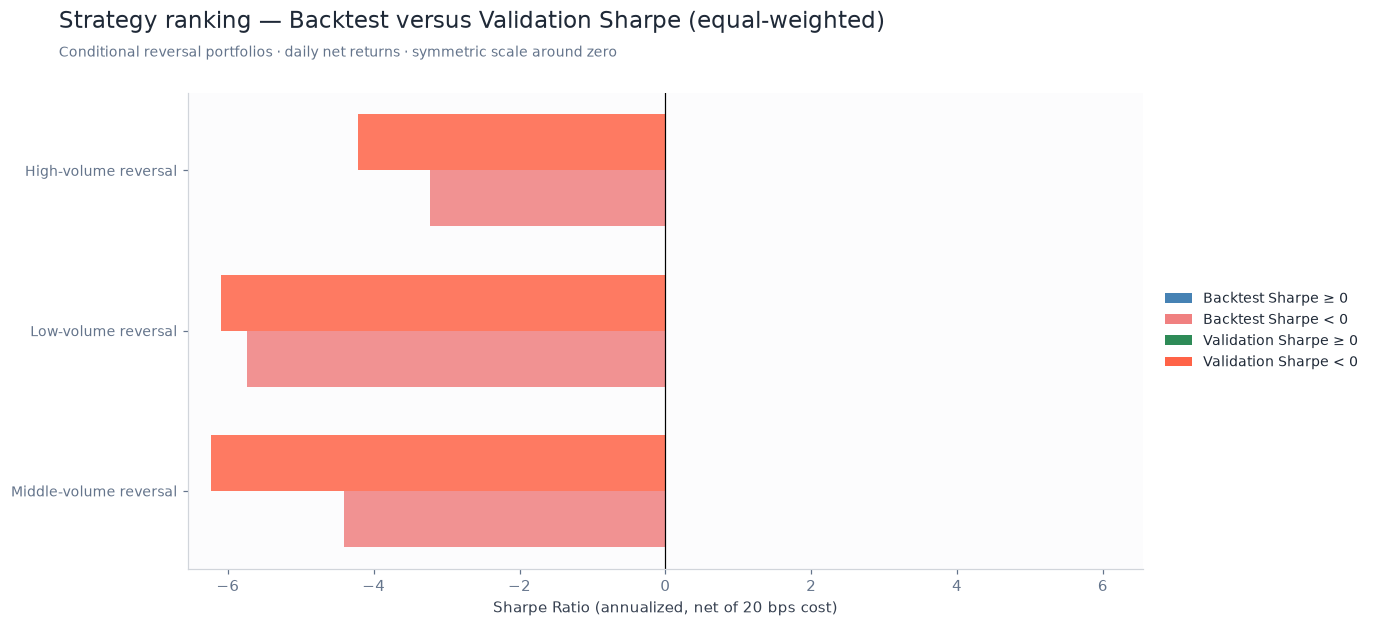

### Value-weighted Backtest-to-validation comparison

,Backtest Sharpe,Validation Sharpe,Sharpe change
Strategy,,,
High-volume reversal,-2.1857,-4.5935,-2.4078
Low-volume reversal,-5.5558,-6.0433,-0.4874
Middle-volume reversal,-4.4115,-6.3533,-1.9418


In [8]:
comparison = pd.DataFrame([
    {"Strategy": LABELS[key],
     "Backtest Sharpe": metrics.loc[("Backtest", key, "equal", "net"), "Sharpe"],
     "Validation Sharpe": metrics.loc[("Validation", key, "equal", "net"), "Sharpe"],
     "Sharpe change": metrics.loc[("Validation", key, "equal", "net"), "Sharpe"] - metrics.loc[("Backtest", key, "equal", "net"), "Sharpe"],
     "Primary paper strategy": key == "lvr"}
    for key in STRATEGIES
]).set_index("Strategy").sort_values("Validation Sharpe", ascending=False)
display(comparison)

y = np.arange(len(comparison))
bar_height = 0.35
fig, ax = plt.subplots(figsize=(13, 5.8))
backtest_colors = ["steelblue" if value >= 0 else "lightcoral" for value in comparison["Backtest Sharpe"]]
validation_colors = ["seagreen" if value >= 0 else "tomato" for value in comparison["Validation Sharpe"]]
ax.barh(y + bar_height / 2, comparison["Backtest Sharpe"].to_numpy(), bar_height,
        color=backtest_colors, label="Backtest", alpha=0.85)
validation_bars = ax.barh(y - bar_height / 2, comparison["Validation Sharpe"].to_numpy(), bar_height,
                          color=validation_colors, label="Validation", alpha=0.85)
warning_flags = []
for bar, backtest_value, validation_value in zip(
        validation_bars, comparison["Backtest Sharpe"], comparison["Validation Sharpe"]):
    flagged = backtest_value > 0 and validation_value < 0.5 * backtest_value
    warning_flags.append(flagged)
    if flagged:
        bar.set_edgecolor("red")
        bar.set_linewidth(2.0)

ax.set_yticks(y)
ax.set_yticklabels(comparison.index, fontsize=9)
ax.invert_yaxis()
sharpe_limit = 1.05 * np.nanmax(np.abs(comparison[["Backtest Sharpe", "Validation Sharpe"]].to_numpy()))
ax.set_xlim(-sharpe_limit, sharpe_limit)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Sharpe Ratio (annualized, net of 20 bps cost)")
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor="steelblue", label="Backtest Sharpe ≥ 0"),
    Patch(facecolor="lightcoral", label="Backtest Sharpe < 0"),
    Patch(facecolor="seagreen", label="Validation Sharpe ≥ 0"),
    Patch(facecolor="tomato", label="Validation Sharpe < 0"),
]
if any(warning_flags):
    legend_handles.append(Patch(facecolor="none", edgecolor="red", linewidth=2,
                                label="Validation Sharpe < 50% of positive backtest Sharpe"))
ax.legend(handles=legend_handles, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
show_figure(fig, "strategy_train_validation_sharpe",
            "Strategy ranking — Backtest versus Validation Sharpe (equal-weighted)",
            "Conditional reversal portfolios · daily net returns · symmetric scale around zero")

comparison_vw = pd.DataFrame([
    {"Strategy": LABELS[key],
     "Backtest Sharpe": metrics.loc[("Backtest", key, "value", "net"), "Sharpe"],
     "Validation Sharpe": metrics.loc[("Validation", key, "value", "net"), "Sharpe"],
     "Sharpe change": metrics.loc[("Validation", key, "value", "net"), "Sharpe"] - metrics.loc[("Backtest", key, "value", "net"), "Sharpe"]}
    for key in STRATEGIES
]).set_index("Strategy").sort_values("Validation Sharpe", ascending=False)
display(Markdown("### Value-weighted Backtest-to-validation comparison"))
display(comparison_vw)

### Signal-timing sensitivity (declared, not used for selection)

The primary specification is fixed by the paper's Eq. (2): the return and volume signals both come from formation day $t$. The table repeats the equal-weighted 3×3 sort under the two alternatives declared in §2, using the same cost engine and active-date statistics. It shows how much the conclusions depend on signal timing; it does **not** pick a winner. Because the validation period has already been examined, any timing that looks better here must be treated as a hypothesis for genuinely new data, not as a result.

In [9]:
timing_specs = {"primary": "Primary (paper Eq. 2): r(t), v(t)"} | {key: spec[0] for key, spec in TIMING_VARIANTS.items()}
timing_rows = []
for period in ["Backtest", "Validation"]:
    for variant, label in timing_specs.items():
        suffix = "" if variant == "primary" else f"_{variant}"
        frames = {key: results[(period, f"{key}{suffix}", "equal")] for key in STRATEGIES}
        for basis in ["gross", "net"]:
            row = {"Period": period, "Timing": label, "Basis": basis}
            for key, frame in frames.items():
                r = active_returns(frame, basis)
                row[f"{key} mean (%/day)"] = 100 * r.mean()
                row[f"{key} Sharpe"] = np.sqrt(PERIODS_PER_YEAR) * r.mean() / r.std(ddof=1)
            act = active_mask(frames["lvr"]) | active_mask(frames["hvr"])
            diff_test = mean_test((frames["lvr"][basis] - frames["hvr"][basis])[act])
            row["lvr - hvr HAC t"] = diff_test["HAC t-stat"]
            row["lvr - hvr HAC p"] = diff_test["HAC p-value"]
            timing_rows.append(row)
timing_sensitivity = pd.DataFrame(timing_rows).set_index(["Period", "Timing", "Basis"])
display(Markdown("### Equal-weighted conditional reversal under alternative signal timings"))
display(timing_sensitivity)


### Equal-weighted conditional reversal under alternative signal timings

lvr mean (%/day)  \
Period     Timing                            Basis                     
Backtest   Primary (paper Eq. 2): r(t), v(t) gross           -0.1663   
                                             net             -0.8174   
           Skip-day aligned: r(t-1), v(t-1)  gross            0.1021   
                                             net             -0.5500   
           Legacy hybrid (v4): r(t-1), v(t)  gross           -0.0263   
                                             net             -0.6831   
Validation Primary (paper Eq. 2): r(t), v(t) gross           -0.0047   
                                             net             -0.6508   
           Skip-day aligned: r(t-1), v(t-1)  gross            0.0931   
                                             net             -0.5540   
           Legacy hybrid (v4): r(t-1), v(t)  gross            0.0649   
                                             net             -0.5837   

                                                    lvr Sharpe  \
Period     Timing                            Basis               
Backtest   Primary (paper Eq. 2): r(t), v(t) gross     -1.1630   
                                             net       -5.7430   
           Skip-day aligned: r(t-1), v(t-1)  gross      0.6919   
                                             net       -3.7503   
           Legacy hybrid (v4): r(t-1), v(t)  gross     -0.1935   
                                             net       -5.0498   
Validation Primary (paper Eq. 2): r(t), v(t) gross     -0.0442   
                                             net       -6.0983   
           Skip-day aligned: r(t-1), v(t-1)  gross      0.9091   
                                             net       -5.4324   
           Legacy hybrid (v4): r(t-1), v(t)  gross      0.6471   
                                             net       -5.8628   

                                                    mvr mean (%/day)  \
Period     Timing                            Basis                     
Backtest   Primary (paper Eq. 2): r(t), v(t) gross           -0.0881   
                                             net             -0.7892   
           Skip-day aligned: r(t-1), v(t-1)  gross           -0.0028   
                                             net             -0.7049   
           Legacy hybrid (v4): r(t-1), v(t)  gross           -0.0001   
                                             net             -0.7031   
Validation Primary (paper Eq. 2): r(t), v(t) gross           -0.0454   
                                             net             -0.7446   
           Skip-day aligned: r(t-1), v(t-1)  gross            0.0285   
                                             net             -0.6716   
           Legacy hybrid (v4): r(t-1), v(t)  gross            0.0748   
                                             net             -0.6312   

                                                    mvr Sharpe  \
Period     Timing                            Basis               
Backtest   Primary (paper Eq. 2): r(t), v(t) gross     -0.4890   
                                             net       -4.4092   
           Skip-day aligned: r(t-1), v(t-1)  gross     -0.0156   
                                             net       -3.9954   
           Legacy hybrid (v4): r(t-1), v(t)  gross     -0.0008   
                                             net       -3.8022   
Validation Primary (paper Eq. 2): r(t), v(t) gross     -0.3775   
                                             net       -6.2347   
           Skip-day aligned: r(t-1), v(t-1)  gross      0.2259   
                                             net       -5.3301   
           Legacy hybrid (v4): r(t-1), v(t)  gross      0.6233   
                                             net       -5.2897   

                                                    hvr mean (%/day)  \
Period     Timing                            Basis                     
Backtest   Primary (paper Eq. 2): r(t), 

## 7. Nine-cell portfolio diagnostics

The nine-cell tables report mean next-day **gross** returns. Rows are formation-day return terciles and columns are within-row volume-shock terciles. Within any column, subtracting the high-return row from the low-return row produces that volume group's reversal spread. These tables expose the mechanism directly without adding a duplicate heatmap.


In [10]:
cell_returns = pd.DataFrame({
    f"R{return_group + 1}_V{volume_group + 1}":
        (weights_frame.shift(1).reindex(returns.index).fillna(0) * returns).sum(axis=1)
    for (return_group, volume_group), weights_frame in cell_weights.items()
})
cell_mean_tables = {}
for period, start, end in [("Backtest", BACKTEST_START, BACKTEST_END),
                           ("Validation", VALIDATION_START, VALIDATION_END)]:
    dates = returns.loc[start:end].index
    dates = dates[holding_ready.loc[dates].to_numpy()]  # active holding dates only (no warm-up cash)
    table = pd.DataFrame(index=["Low prior return", "Middle prior return", "High prior return"],
                         columns=["Low volume shock", "Middle volume shock", "High volume shock"], dtype=float)
    for return_group in range(3):
        for volume_group in range(3):
            table.iloc[return_group, volume_group] = 100 * cell_returns.loc[
                dates, f"R{return_group + 1}_V{volume_group + 1}"].mean()
    cell_mean_tables[period] = table
    display(Markdown(f"### {period}: nine-cell mean daily gross return (%)"))
    display(table)


### Backtest: nine-cell mean daily gross return (%)

,Low volume shock,Middle volume shock,High volume shock
Low prior return,0.0850,0.1268,0.1319
Middle prior return,0.1964,0.2461,0.3791
High prior return,0.2513,0.2149,0.1908


### Validation: nine-cell mean daily gross return (%)

,Low volume shock,Middle volume shock,High volume shock
Low prior return,-0.0622,-0.1035,-0.0699
Middle prior return,-0.0687,-0.1772,-0.0786
High prior return,-0.0575,-0.0581,-0.0363


## 8. Standardized daily performance and representative accounts

The standardized tables above use the common daily performance definitions. The figures below show the equal-weighted `lvr`, `mvr`, and `hvr` accounts using net returns after the fixed 20-bps fee. Each period starts from cash; the first panel also includes gross `lvr` and a fee-adjusted BTC buy-and-hold benchmark.

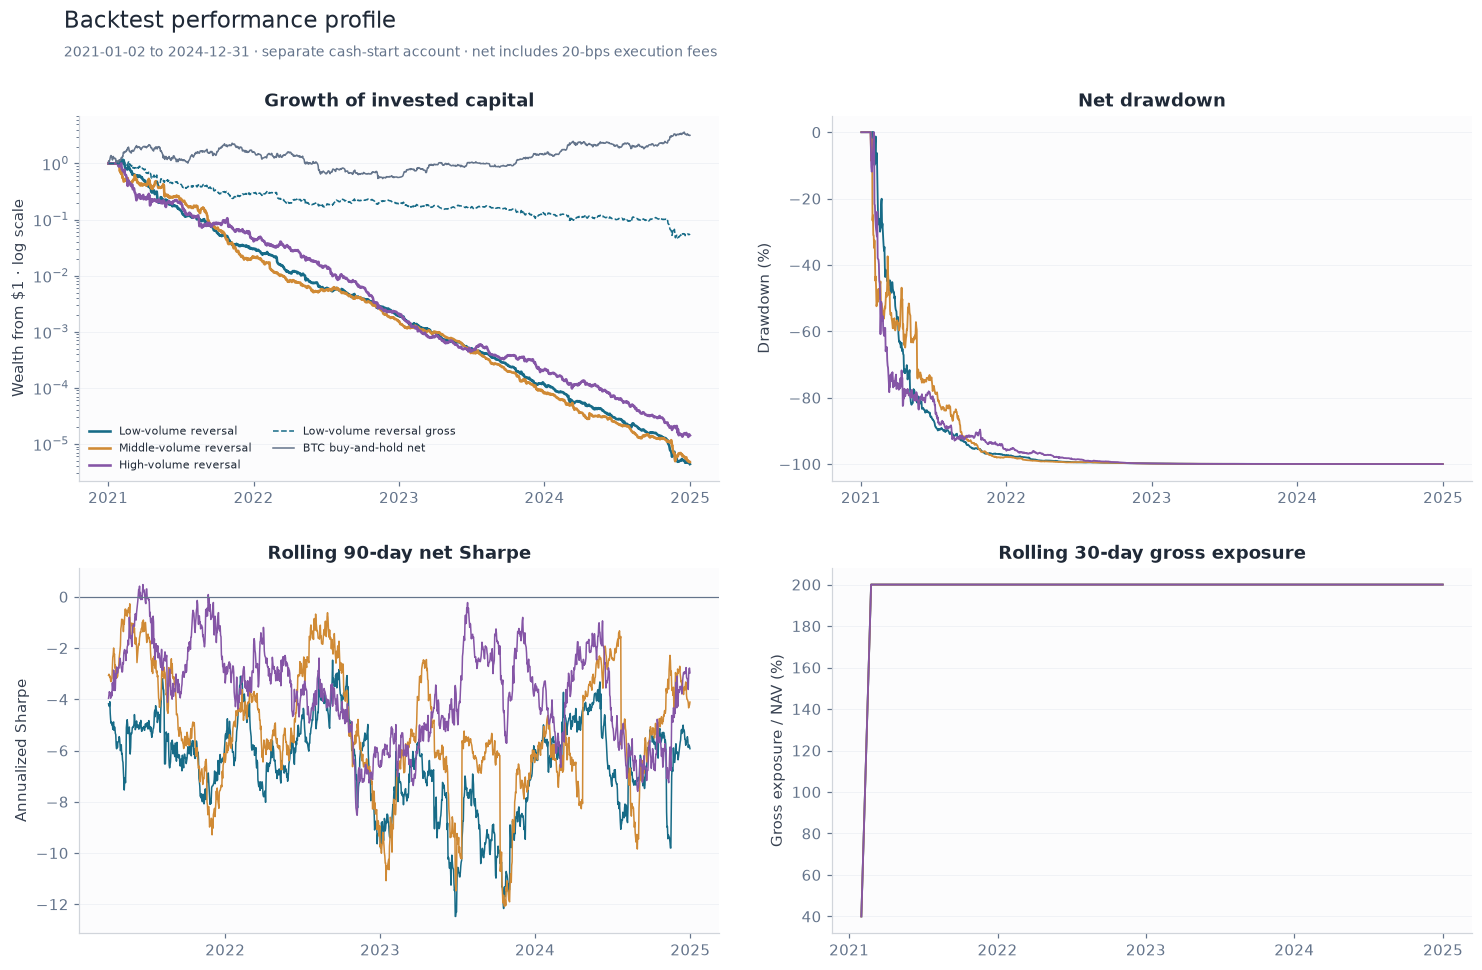

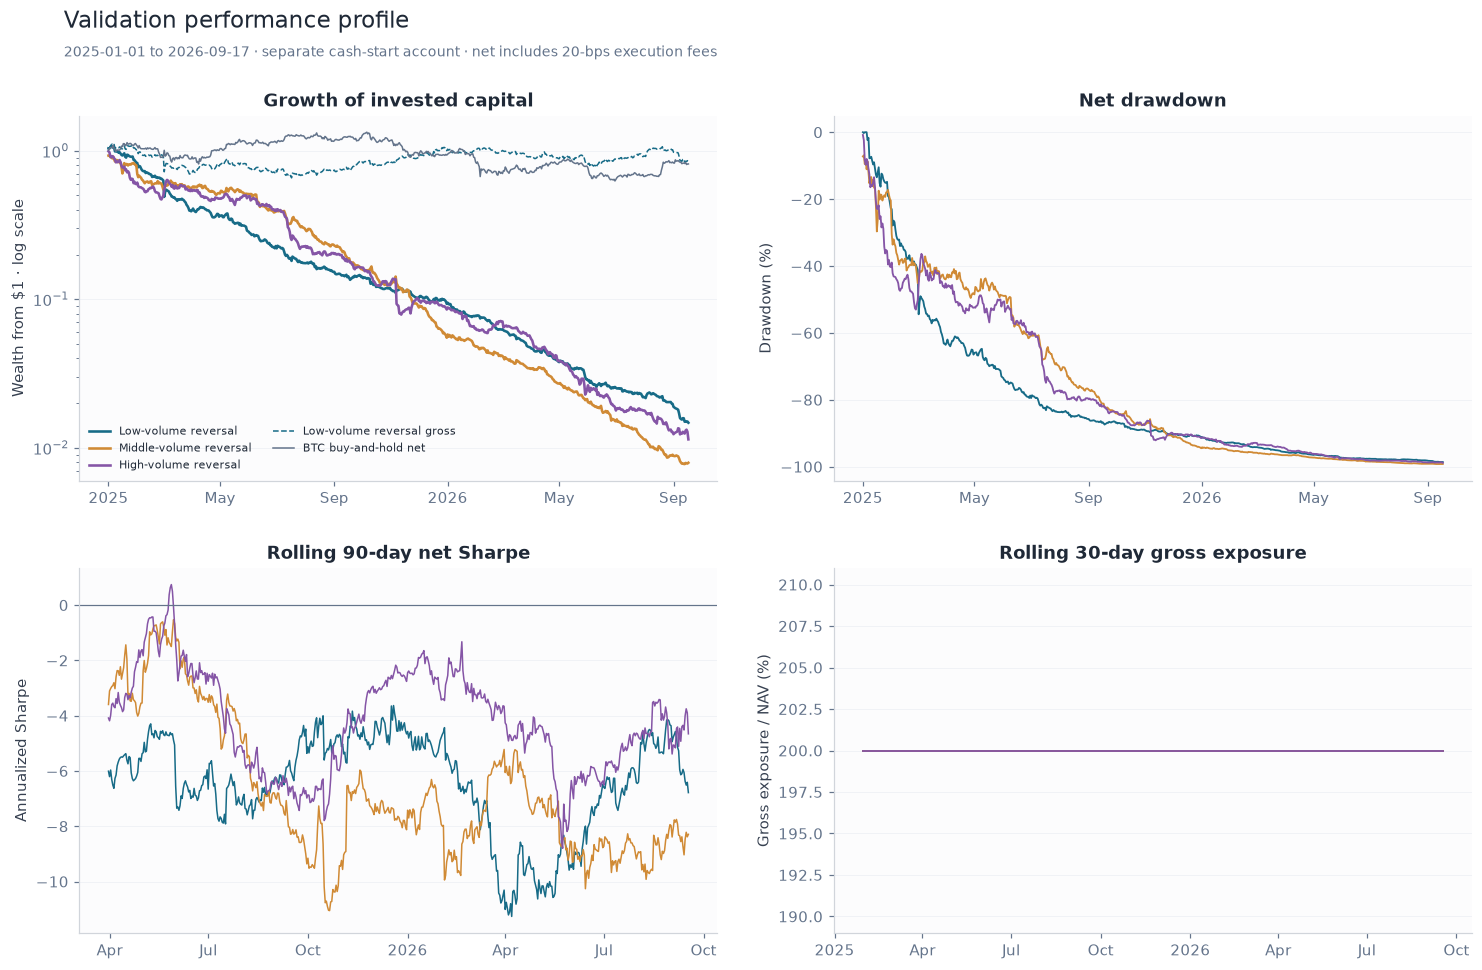

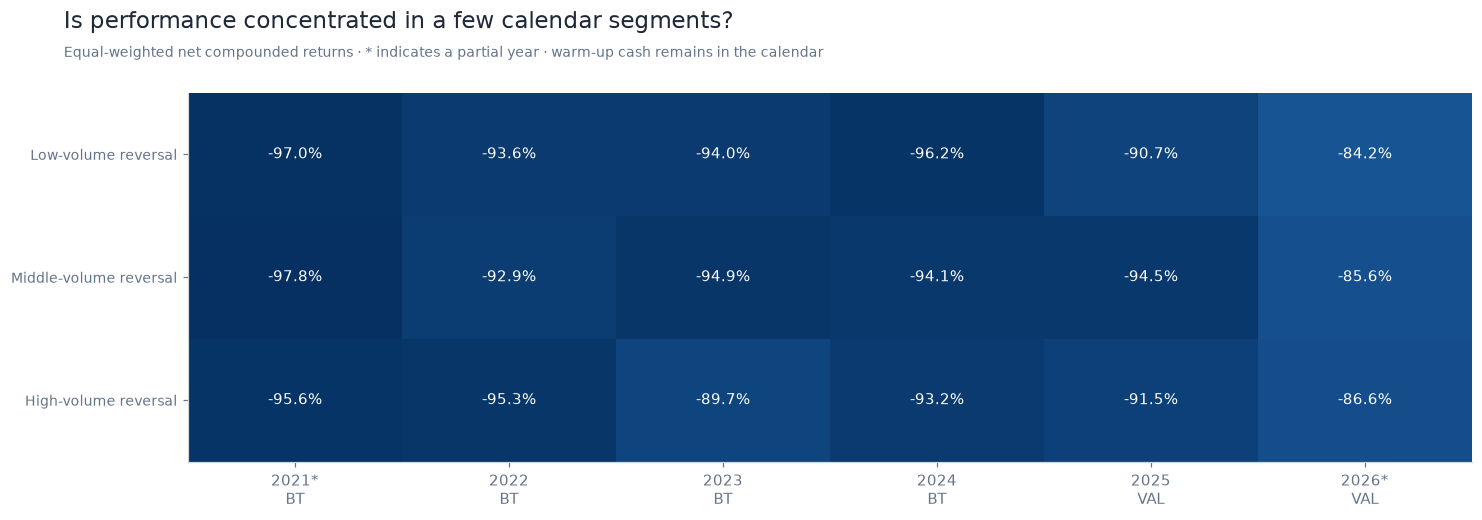

In [11]:
focus_keys = list(STRATEGIES)
benchmark_results = {}
for period, start, end in [("Backtest", BACKTEST_START, BACKTEST_END),
                           ("Validation", VALIDATION_START, VALIDATION_END)]:
    dates = returns.loc[start:end].index
    btc_holdings = pd.DataFrame(0.0, index=dates, columns=ASSETS)
    btc_holdings["BTC-USD"] = 1.0
    benchmark_results[(period, "BTC buy-and-hold")], _ = evaluate_segment(
        btc_holdings, returns.loc[dates])

    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for key in focus_keys:
        frame = results[(period, key, "equal")]
        color = COLORS[key]
        wealth, drawdown = wealth_and_drawdown(frame.net)
        axes[0, 0].plot(dates, wealth, color=color, label=LABELS[key], linewidth=1.7)
        axes[0, 1].plot(dates, drawdown * 100, color=color, linewidth=1.2)
        rolling = frame.net.rolling(90, min_periods=90)
        axes[1, 0].plot(dates, np.sqrt(PERIODS_PER_YEAR) * rolling.mean() / rolling.std(),
                        color=color, linewidth=1.0)
        axes[1, 1].plot(dates, 100 * frame.gross_exposure.rolling(30, min_periods=30).mean(),
                        color=color, linewidth=1.2)

    lvr_gross = results[(period, "lvr", "equal")].gross
    btc_net = benchmark_results[(period, "BTC buy-and-hold")].net
    axes[0, 0].plot(dates, (1 + lvr_gross).cumprod(), color=COLORS["lvr"],
                    linestyle="--", linewidth=1.0, label="Low-volume reversal gross")
    axes[0, 0].plot(dates, (1 + btc_net).cumprod(), color="#64748b",
                    linewidth=1.0, label="BTC buy-and-hold net")
    axes[0, 0].set_yscale("log")
    axes[0, 0].legend(fontsize=7, ncol=2)
    for ax, title, ylabel in [
            (axes[0, 0], "Growth of invested capital", "Wealth from $1 · log scale"),
            (axes[0, 1], "Net drawdown", "Drawdown (%)"),
            (axes[1, 0], "Rolling 90-day net Sharpe", "Annualized Sharpe"),
            (axes[1, 1], "Rolling 30-day gross exposure", "Gross exposure / NAV (%)")]:
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        polish_axis(ax, date_axis=True)
    axes[1, 0].axhline(0, color="#64748b", linewidth=0.8)
    show_figure(fig, f"{period.lower()}_performance", f"{period} performance profile",
                f"{dates[0].date()} to {dates[-1].date()} · separate cash-start account · net includes 20-bps execution fees")

calendar_rows = []
for period in ["Backtest", "Validation"]:
    for key in focus_keys:
        frame = results[(period, key, "equal")]
        for year, chunk in frame.groupby(frame.index.year):
            calendar_rows.append({"Period": period, "Year": year, "Strategy": key,
                                  "N dates": len(chunk),
                                  "Net return (%)": 100 * ((1 + chunk.net).prod() - 1)})
calendar_returns = pd.DataFrame(calendar_rows).set_index(["Period", "Year", "Strategy"]).sort_index()
calendar_wide = calendar_returns["Net return (%)"].unstack("Strategy").reindex(columns=focus_keys)
fig, ax = plt.subplots(figsize=(14, 4.8))
values = calendar_wide.to_numpy().T
bound = max(np.nanmax(np.abs(values)), 1)
ax.imshow(values, cmap="RdBu_r", vmin=-bound, vmax=bound, aspect="auto")
for (row, col), value in np.ndenumerate(values):
    ax.text(col, row, f"{value:+.1f}%", ha="center", va="center",
            color="white" if abs(value) > 0.6 * bound else "#1f2937", fontsize=10)
calendar_labels = []
for period, year in calendar_wide.index:
    n_dates = calendar_returns.loc[(period, year)].iloc[0]["N dates"]
    expected = 366 if pd.Timestamp(year, 12, 31).is_leap_year else 365
    calendar_labels.append(f"{year}{'*' if n_dates != expected else ''}\n{'BT' if period == 'Backtest' else 'VAL'}")
ax.set_xticks(range(len(calendar_labels)), calendar_labels)
ax.set_yticks(range(len(focus_keys)), [LABELS[key] for key in focus_keys], fontsize=9)
show_figure(fig, "calendar_returns", "Is performance concentrated in a few calendar segments?",
            "Equal-weighted net compounded returns · * indicates a partial year · warm-up cash remains in the calendar")

### Volume-shock window robustness (`m=60`)

The paper reports `m=60` as a robustness check on the volume-shock window and expects "qualitatively identical conclusions." The `lvr`/`mvr`/`hvr` holdings built with `volume_shock_m60` (equal-weighted; the double-sort formation return, sorting logic, and cost model are otherwise identical to the `m=30` baseline) were already evaluated alongside everything else in §4 as `results[(period, f"{key}_m60", "equal")]`. This section only compares the two windows directly.

### Net Sharpe: m=30 baseline vs m=60 robustness (equal-weighted, common active dates only)

Common active dates  Sharpe (m=30)  \
Period     Strategy                                                     
Backtest   Low-volume reversal                    1412        -5.8085   
           Middle-volume reversal                 1412        -4.4029   
           High-volume reversal                   1412        -3.1307   
Validation Low-volume reversal                     625        -6.0983   
           Middle-volume reversal                  625        -6.2347   
           High-volume reversal                    625        -4.2160   

                                   Sharpe (m=60)  Difference  
Period     Strategy                                           
Backtest   Low-volume reversal           -5.8168     -0.0083  
           Middle-volume reversal        -4.9409     -0.5380  
           High-volume reversal          -2.7669      0.3638  
Validation Low-volume reversal           -5.8962      0.2020  
           Middle-volume reversal        -6.6572     -0.4226  
           High-volume reversal          -3.9927      0.2233

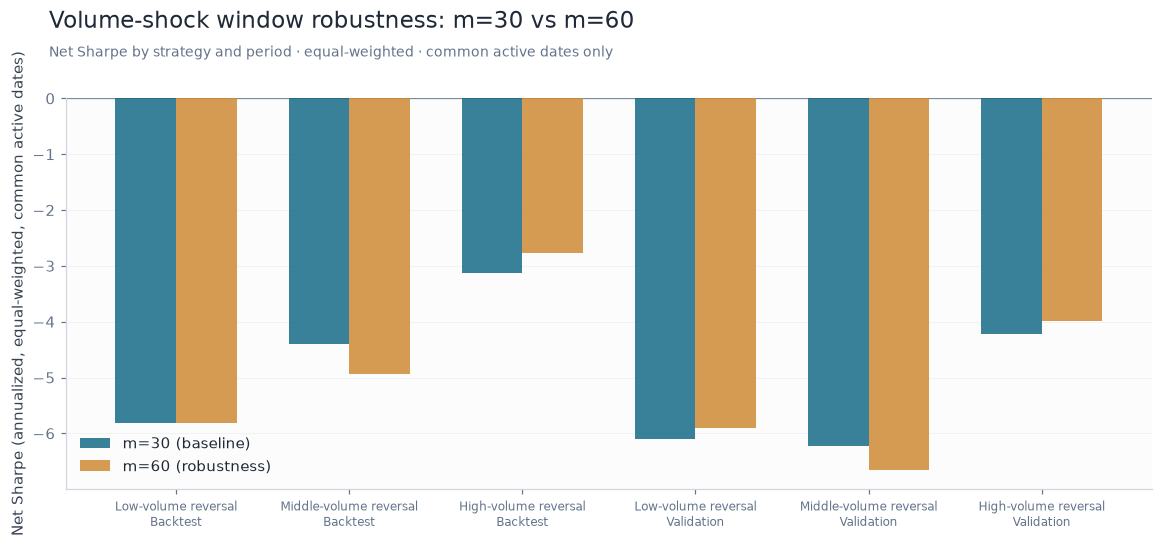

In [12]:
def common_date_sharpe(frame_a, frame_b, basis="net"):
    """Sharpe for both variants restricted to dates where BOTH have an active (nonzero-gross)
    holding, so the longer m=60 signal warm-up does not inflate its Sharpe with additional
    zero-return dates."""
    active = (frame_a["gross_exposure"] > 1e-12) & (frame_b["gross_exposure"] > 1e-12)
    ra, rb = frame_a.loc[active, basis], frame_b.loc[active, basis]
    sharpe_a = np.sqrt(PERIODS_PER_YEAR) * ra.mean() / ra.std(ddof=1) if ra.std(ddof=1) > 0 else np.nan
    sharpe_b = np.sqrt(PERIODS_PER_YEAR) * rb.mean() / rb.std(ddof=1) if rb.std(ddof=1) > 0 else np.nan
    return sharpe_a, sharpe_b, int(active.sum())


m60_rows = []
for period in ["Backtest", "Validation"]:
    for key in STRATEGIES:
        sharpe_m30, sharpe_m60, common_n = common_date_sharpe(
            results[(period, key, "equal")], results[(period, f"{key}_m60", "equal")])
        m60_rows.append({"Period": period, "Strategy": LABELS[key], "Common active dates": common_n,
                         "Sharpe (m=30)": sharpe_m30, "Sharpe (m=60)": sharpe_m60,
                         "Difference": sharpe_m60 - sharpe_m30})
m60_comparison = pd.DataFrame(m60_rows).set_index(["Period", "Strategy"])
display(Markdown("### Net Sharpe: m=30 baseline vs m=60 robustness (equal-weighted, common active dates only)"))
display(m60_comparison)

fig, ax = plt.subplots(figsize=(11, 5))
width = 0.35
strategies_list = list(STRATEGIES)
x = np.arange(len(strategies_list) * 2)
labels_x = [f"{LABELS[k]}\n{p}" for p in ["Backtest", "Validation"] for k in strategies_list]
sharpe30 = [m60_comparison.loc[(p, LABELS[k]), "Sharpe (m=30)"] for p in ["Backtest", "Validation"] for k in strategies_list]
sharpe60 = [m60_comparison.loc[(p, LABELS[k]), "Sharpe (m=60)"] for p in ["Backtest", "Validation"] for k in strategies_list]
ax.bar(x - width / 2, sharpe30, width, label="m=30 (baseline)", color="#176b87", alpha=0.85)
ax.bar(x + width / 2, sharpe60, width, label="m=60 (robustness)", color="#d08a35", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(labels_x, fontsize=8)
polish_axis(ax, zero_line=True)
ax.set_ylabel("Net Sharpe (annualized, equal-weighted, common active dates)")
ax.legend()
show_figure(fig, "volume_window_robustness", "Volume-shock window robustness: m=30 vs m=60",
            "Net Sharpe by strategy and period · equal-weighted · common active dates only")

## 9. Reproducible research outputs

The notebook writes strategy returns, holdings, trades, standardized metrics, comparison tables, calendar returns, benchmark returns, and robustness results directly to `output/liquidity_provision/`. Filenames are stable, so rerunning the notebook replaces the previous results instead of creating an opaque run-number folder.

In [13]:
specification = {
    "study": "bianchi_fixed_universe_conditional_reversal",
    "specification_version": 5,
    "sample_start": SAMPLE_START, "sample_end": SAMPLE_END, "assets": ASSETS,
    "backtest_start": BACKTEST_START, "backtest_end": BACKTEST_END,
    "validation_start": VALIDATION_START, "validation_end": VALIDATION_END,
    "backtest_dates": len(returns.loc[BACKTEST_START:BACKTEST_END]),
    "validation_dates": len(returns.loc[VALIDATION_START:VALIDATION_END]),
    "primary_input": INPUT_PATH.name, "market_cap_input": MCAP_PATH.name,
    "volume_window": VOLUME_WINDOW, "volume_window_robustness": VOLUME_WINDOW_ROBUSTNESS,
    "signal_timing": "return_over_day_t_and_volume_shock_at_t_formed_at_close_t_holdings_earn_t_to_t_plus_1",
    "signal_timing_source": "paper_eq2_y_t_plus_1_on_contemporaneous_y_t_and_v_t",
    "signal_timing_sensitivities": {key: spec[0] for key, spec in TIMING_VARIANTS.items()},
    "volume_baseline": "log_arithmetic_mean_of_prior_raw_volume",
    "volume_standardization": "sample_std_of_prior_log_volume",
    "volume_window_min_valid_fraction": VOLUME_MIN_OBS_FRACTION,
    "sort": "return_terciles_on_return_signal_then_within_return_volume_terciles_on_volume_shock",
    "weightings": list(WEIGHTINGS), "gross_exposure": 2.0, "net_exposure": 0.0,
    "min_valid_assets_to_trade": MIN_VALID_ASSETS,
    "wash_trade_filter": "volume_to_market_cap_ratio_above_1_masked_per_coin_day_not_pair_level",
    "statistics_sample": "active_holding_or_trading_dates_only",
    "cost_bps_per_asset_dollar": COST_BPS,
    "cost_model": "actual_notional_with_weight_drift_and_post_fee_targets",
    "segment_accounts": "independent_cash_start_and_final_liquidation",
    "invalid_signal_policy": "per_asset_exclusion_from_that_days_sort_not_universe_wide_flatten",
    "backtest_start_policy": "fixed_declared_70_30_split",
    "input_sha256": input_hashes,
}
OUTPUT_DIR = OUTPUT_ROOT
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

daily_export = pd.concat(results, names=["period", "strategy", "weighting"], sort=False)
ledger_export = pd.concat(trade_ledgers, names=["period", "strategy", "weighting"], sort=False).reset_index(level=-1, drop=True)
holdings_export = pd.concat({f"{k}__{w}": v for (k, w), v in ALL_HOLDINGS.items()}, names=["strategy_weighting", "return_date"], sort=False)

for filename, obj in {
    "daily_returns_and_costs.csv": daily_export,
    "holding_weights.csv": holdings_export,
    "trades.csv": ledger_export,
    "metrics.csv": metrics,
    "zero_tests.csv": zero_tests,
    "paired_mean_tests.csv": paired_tests,
    "decile_benchmarks.csv": benchmark_table,
    "backtest_validation_comparison_ew.csv": comparison,
    "backtest_validation_comparison_vw.csv": comparison_vw,
    "coverage.csv": coverage_table,
    "nine_cell_daily_gross_returns.csv": cell_returns,
    "volume_issues.csv": volume_issues,
    "wash_trade_issues.csv": wash_trade_issues,
    "market_cap_issues.csv": market_cap_issues,
    "m60_robustness.csv": m60_comparison,
    "timing_sensitivity.csv": timing_sensitivity,
    "volume_quality.csv": volume_quality,
    "signal_coverage.csv": signal_coverage,
    "calendar_returns.csv": calendar_returns,
    "benchmark_daily_returns.csv": pd.concat(benchmark_results, names=["period", "benchmark", "return_date"]),
}.items():
    obj.to_csv(OUTPUT_DIR / filename)

manifest = {
    "specification": specification,
    "environment": {"python": platform.python_version(), "numpy": np.__version__,
                    "pandas": pd.__version__, "statsmodels": sm.__version__},
    "notebook_source_sha256": hashlib.sha256(json.dumps(
        [cell["source"] for cell in json.loads((NOTEBOOK_DIR / NOTEBOOK_NAME).read_text())["cells"]],
        sort_keys=True).encode()).hexdigest(),
    "figure_names": list(FIGURES),
    "validation_previously_explored": True,
}
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))
for old_figure in OUTPUT_DIR.glob("*.png"):
    if old_figure.stem not in FIGURES:
        old_figure.unlink()
for figure_name, saved_figure in FIGURES.items():
    saved_figure.savefig(OUTPUT_DIR / f"{figure_name}.png", dpi=160, bbox_inches="tight")
print(f"Exported reproducible results and {len(FIGURES)} figure(s) to {OUTPUT_DIR.relative_to(NOTEBOOK_DIR).as_posix()}/.")

Exported reproducible results and 5 figure(s) to output/liquidity_provision/.


## 10. Core findings and interpretation

The primary sort uses formation-day return and volume shock together, with the weights earning the next day's return. Skip-day and legacy hybrid timings are sensitivities; they do not choose the primary specification. Low-volume reversal is predeclared, so validation does not select a replacement.

The tables below report current gross and net performance, individual raw HAC mean tests, and the low-minus-high-volume paired test. Statistical significance and the sign of the effect are separate: a significantly negative reversal spread does not support a positive reversal premium. Read relative rankings alongside absolute returns and implementation costs.

Daily +100%/−100% targets can generate substantial traded notional. Net results include the 20-bps traded-notional fee; short availability, financing, market impact, and margin constraints remain unmodeled. The `m=60` and timing sensitivities are reported in the earlier sections rather than selected from their outcomes.

The fixed 30-coin CMC universe produces small 3×3 cells and differs from the paper's historical exchange universe. Screened volume and market-cap observations are exported for review. Metrics use active dates, as documented in Section 5. Both periods have already been examined, so this is historical evidence rather than an untouched prospective test.


In [14]:
# Generate the conclusion from the current primary-timing exports.
conclusion_metrics = pd.read_csv(OUTPUT_DIR / "metrics.csv")
conclusion_primary = conclusion_metrics.loc[conclusion_metrics.Strategy.isin(["lvr", "mvr", "hvr"])]
display(conclusion_primary[["Period", "Strategy", "Weighting", "Basis", "CAGR (%)", "Sharpe", "Annual turnover"]].round(3))
display(Markdown("**Raw HAC mean tests:** compare the effect sign with its p-value; these individual tests do not adjust for the full research search."))
display(pd.read_csv(OUTPUT_DIR / "zero_tests.csv").round(4))
display(Markdown("**Paired low-volume minus high-volume comparison:**"))
display(pd.read_csv(OUTPUT_DIR / "paired_mean_tests.csv").round(4))


,Period,Strategy,Weighting,Basis,CAGR (%),Sharpe,Annual turnover
0,Backtest,lvr,equal,gross,-52.6130,-1.1630,1190.3890
1,Backtest,lvr,equal,net,-95.6530,-5.7430,1190.3890
2,Backtest,mvr,equal,gross,-42.0150,-0.4890,1280.5500
3,Backtest,mvr,equal,net,-95.5630,-4.4090,1280.5500
4,Backtest,hvr,equal,gross,-41.1950,-0.2740,1149.0580
5,Backtest,hvr,equal,net,-94.1380,-3.2220,1149.0580
10,Backtest,lvr,value,gross,-67.9370,-1.4750,1278.0590
11,Backtest,lvr,value,net,-97.5350,-5.5560,1278.0590
12,Backtest,mvr,value,gross,-52.0230,-0.6710,1322.4120
13,Backtest,mvr,value,net,-96.6260,-4.4120,1322.4120


**Raw HAC mean tests:** compare the effect sign with its p-value; these individual tests do not adjust for the full research search.

,Period,Weighting,Basis,Strategy,Mean daily (%),HAC t-stat,HAC p-value
0,Backtest,Equal-weighted,gross,Low-volume reversal,-0.1663,-2.5333,0.0114
1,Backtest,Equal-weighted,gross,Middle-volume reversal,-0.0881,-1.0270,0.3046
2,Backtest,Equal-weighted,gross,High-volume reversal,-0.0589,-0.6531,0.5138
3,Backtest,Equal-weighted,net,Low-volume reversal,-0.8174,-12.5532,0.0000
4,Backtest,Equal-weighted,net,Middle-volume reversal,-0.7892,-9.2981,0.0000
5,Backtest,Equal-weighted,net,High-volume reversal,-0.6882,-7.7872,0.0000
6,Backtest,Value-weighted,gross,Low-volume reversal,-0.2546,-2.8936,0.0039
7,Backtest,Value-weighted,gross,Middle-volume reversal,-0.1306,-1.6321,0.1029
8,Backtest,Value-weighted,gross,High-volume reversal,0.0832,0.7324,0.4640
9,Backtest,Value-weighted,net,Low-volume reversal,-0.9532,-10.9742,0.0000


**Paired low-volume minus high-volume comparison:**

,Period,Weighting,Basis,Difference,Mean daily (%),HAC t-stat,HAC p-value
0,Backtest,Equal-weighted,gross,Low minus high volume reversal,-0.1074,-0.9799,0.3273
1,Backtest,Equal-weighted,net,Low minus high volume reversal,-0.1292,-1.2049,0.2284
2,Backtest,Value-weighted,gross,Low minus high volume reversal,-0.3379,-2.4395,0.0148
3,Backtest,Value-weighted,net,Low minus high volume reversal,-0.3605,-2.6320,0.0086
4,Validation,Equal-weighted,gross,Low minus high volume reversal,0.0289,0.2019,0.8400
5,Validation,Equal-weighted,net,Low minus high volume reversal,0.0145,0.1022,0.9187
6,Validation,Value-weighted,gross,Low minus high volume reversal,0.0987,0.5942,0.5526
7,Validation,Value-weighted,net,Low minus high volume reversal,0.0685,0.4163,0.6773
